# Rigorous evaluation of non-invasive questionnaire features for classifying chronic kidney disease in diabetic patients

### Analysis notebook for the manuscript (`diabetic-ckd-questionnaire-evaluation.ipynb`)

**Everything reported in the manuscript is produced by this notebook**: every table, figure and number. Running it end to end on the public dataset regenerates all outputs in `paper_outputs/` (figures as TIFF + PNG, tables as CSV, all headline numbers in `paper_numbers.json`, and a `run_manifest.json` with software versions, seeds and the dataset checksum).

| | |
|---|---|
| **Data** | BIRDEM General Hospital diabetic cohort, 400 patients × 10 yearly records, 20 questionnaire/record features; Mendeley Data, doi:10.17632/hjkzgbxgv5.2 (CC BY 4.0) |
| **Reporting guidance followed** | TRIPOD+AI (Collins et al., BMJ 2024;385:e078378); PLOS ONE statistical-reporting guidelines (SAMPL-style) |
| **Licence** | Code: MIT. Text, figures and tables: CC BY 4.0. |
| **Code** | https://github.com/PanzerFaustAnan/diabetic-ckd-questionnaire-evaluation |
| **Runtime** | Full run ≈ 25–40 min on a free Colab CPU; `FAST_MODE = True` gives a ≈ 5 min smoke test |

### How to run
1. Open the notebook in Colab (or any Jupyter environment with internet).
2. *Runtime → Run all.* The dataset is downloaded from Mendeley Data automatically and checked against its SHA-256 fingerprint. Nothing needs editing and no Google Drive is used.
3. Offline? Download the CSV from the Mendeley DOI above and set `DATA_PATH` in the first code cell.

### Structure
| Part | Content | Research question |
|---|---|---|
| 1 | Setup, pre-specified protocol, data audit, cohort description, design signature | design and data validity |
| 2 | Primary evaluation: nested repeated cross-validation, optimism correction, permutation test, sample-size adequacy, calibration, clinical utility, subgroups, feature evidence, sensitivity analyses | **RQ1–RQ3** |
| 3 | Management pattern; does time help; sampling-design simulation; single-split variability (simulation, learning curve, public datasets) | **RQ4–RQ7** |
| 4 | Outputs: figure legends, tables, TRIPOD+AI crosswalk, data/code/ethics statement drafts, release checklist | reporting |

## Part 1 · Setup, protocol and data

### 1.1 Configuration

In [30]:
# =========================  CONFIGURATION  =========================
DATA_URL  = "https://data.mendeley.com/public-files/datasets/hjkzgbxgv5/files/cb4eebf8-c225-4adc-a3e6-82e55c5526db/file_downloaded"
DATA_PATH = None   # optional: path to a local copy of the CSV; if set, nothing is downloaded

# SHA-256 fingerprint of the Mendeley v2 file analysed in the manuscript. A mismatch only triggers a warning
# (you may be using another version), but it is then recorded in the run manifest.
EXPECTED_SHA256 = "9cef0eb4cd3279c36f9b4816c6a2ccfd480345ee3a57e2dc5c9f722e92793618"

SEED = 42                     # master seed; every analysis derives its own independent stream from it
FAST_MODE = False             # True = quick smoke test (reduced repeats); False = full paper run
RUN_PUBLIC_DATASETS = True    # corroboration on public OpenML datasets (needs internet; skipped gracefully if offline)
RUN_SHAP_APPENDIX = True     # optional SHAP summary for the supplement
OUT_DIR = "paper_outputs"

import os, sys, re, json, hashlib, warnings, urllib.request
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

def get_dataset(url, local_path=None, out="DiabeticCKD_dataset.csv"):
    """Use a local file if given; otherwise download from Mendeley Data (re-used if already downloaded)."""
    if local_path:
        return local_path
    if not os.path.exists(out):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        try:
            with urllib.request.urlopen(req, timeout=60) as r, open(out, "wb") as f:
                f.write(r.read())
        except Exception as err:
            if IN_COLAB:   # last resort: manual upload
                print(f"Download failed ({err}). Please upload DiabeticCKD_dataset.csv manually.")
                from google.colab import files
                return list(files.upload().keys())[0]
            raise RuntimeError(f"Download failed ({err}). Download the CSV from doi:10.17632/hjkzgbxgv5.2 and set DATA_PATH.")
    with open(out, "rb") as f:
        if f.read(200).lstrip().lower().startswith((b"<!doctype", b"<html")):
            os.remove(out)
            raise RuntimeError("Mendeley returned a web page instead of the CSV; set DATA_PATH to a local copy.")
    return out

DATA_FILE = get_dataset(DATA_URL, DATA_PATH)
assert os.path.exists(DATA_FILE), f"Dataset not found at {DATA_FILE!r}."
print("Dataset file:", DATA_FILE)

Dataset file: DiabeticCKD_dataset.csv


### 1.2 Environment and helper library
All reusable helpers live in this one cell so that the analysis cells below stay short and readable. Three design choices matter for reproducibility:

* **Independent random streams.** `rng_for("name")` derives a generator from the master seed *and the analysis name*, so results do not change if cells are re-ordered or one analysis is re-run.
* **Single source of truth for numbers.** `record(key, value)` stores every number in `paper_numbers.json`.

In [2]:
import io, math, time, zlib, platform, textwrap
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
import sklearn, scipy
import statsmodels, statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss, roc_curve
from sklearn.inspection import permutation_importance

N_JOBS = max(1, (os.cpu_count() or 1))
OUT = Path(OUT_DIR); (OUT / "figures").mkdir(parents=True, exist_ok=True); (OUT / "tables").mkdir(parents=True, exist_ok=True)
T_START = time.time()

# ---- run sizes (full vs smoke test) -------------------------------------------------------------------------
SZ = dict(
    n_repeats   = 3   if FAST_MODE else 10,     # repetitions of 5-fold CV (outer loop)
    n_boot      = 200 if FAST_MODE else 2000,   # bootstrap resamples for confidence intervals
    n_boot_opt  = 50  if FAST_MODE else 300,    # bootstrap resamples for optimism correction (full strategy refitted each time)
    n_perm      = 50  if FAST_MODE else 500,    # label permutations
    n_splits_emp= 60  if FAST_MODE else 300,    # random single splits on the real data
    sim_reps    = 20  if FAST_MODE else 100,    # replicates per simulation cell (split-variability simulation)
    sim_enrich  = 40  if FAST_MODE else 300,    # replicates (case-enriched sampling simulation)
    lc_reps     = 8   if FAST_MODE else 30,     # learning-curve resamples per sample size
    pub_splits  = 30  if FAST_MODE else 100,    # random splits per public dataset
)

# ---- plotting style  -------------------
C = dict(black="#000000", orange="#E69F00", sky="#56B4E9", green="#009E73", yellow="#F0E442", blue="#0072B2", red="#D55E00", purple="#CC79A7", grey="#8C8C8C")

from matplotlib import font_manager
def _setup_arial():
    have = lambda name: any(f.name == name for f in font_manager.fontManager.ttflist)
    if not have("Arial") and IN_COLAB:
        import subprocess
        subprocess.run("echo ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true | debconf-set-selections && "
                       "apt-get -qq install -y ttf-mscorefonts-installer > /dev/null 2>&1", shell=True)
        for f in font_manager.findSystemFonts():
            try: font_manager.fontManager.addfont(f)
            except Exception: pass
    for name in ("Arial", "Liberation Sans"):
        if have(name): return name
    print("WARNING: neither Arial nor Liberation Sans found; figures will use the default font (not PLOS-compliant).")
    return "DejaVu Sans"
FIG_FONT = _setup_arial(); print("Figure font:", FIG_FONT)
FS = 8
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 8.5, "axes.titlesize": 9, "axes.labelsize": 8.5,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "legend.title_fontsize": 8,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "grid.linewidth": .5,
                     "legend.frameon": False, "font.family": "sans-serif", "font.sans-serif": [FIG_FONT, "DejaVu Sans"]})
FIGS, TABLES, RESULTS, DEVIATIONS = {}, {}, {}, []

def rng_for(name):
    """Independent, order-free random stream per analysis."""
    return np.random.default_rng([SEED, zlib.crc32(name.encode())])

def _py(v):
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.floating,)): return float(v)
    if isinstance(v, np.ndarray): return [_py(x) for x in v.tolist()]
    if isinstance(v, dict): return {str(k): _py(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)): return [_py(x) for x in v]
    return v
def record(key, value): RESULTS[key] = _py(value)

def fmt_p(p): return "<0.001" if p < 0.001 else f"{p:.3f}"
def wilson(k, n): lo, hi = proportion_confint(k, n, method="wilson"); return lo, hi
def ci_str(v, lo, hi, d=3): return f"{v:.{d}f} ({lo:.{d}f}-{hi:.{d}f})"

FIG_CHECKS = {}
def save_fig(fig, num, title, legend):
    """Write FigN.tiff (RGB, no alpha, LZW, 300 dpi) and FigN.png, check PLOS size limits, register the legend."""
    from PIL import Image
    p = OUT / "figures" / f"Fig{num}"
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", pad_inches=0.03, facecolor="white"); buf.seek(0)
    im = Image.open(buf).convert("RGB")                         # flatten: PLOS does not accept alpha channels
    im.save(str(p) + ".tiff", compression="tiff_lzw", dpi=(300, 300)); im.save(str(p) + ".png", dpi=(300, 300))
    w_in, h_in = im.size[0] / 300, im.size[1] / 300
    ok = (w_in <= 7.5 + 1e-6) and (h_in <= 8.75 + 1e-6) and (w_in >= 2.63)
    FIG_CHECKS[num] = dict(width_in=round(w_in, 2), height_in=round(h_in, 2), within_plos_limits=bool(ok))
    if not ok: print(f"WARNING: Fig{num} is {w_in:.2f} x {h_in:.2f} in; PLOS allows 2.63-7.5 in wide and at most 8.75 in high.")
    FIGS[num] = dict(title=title, legend=legend, files=[f"Fig{num}.tiff", f"Fig{num}.png"])
    plt.show()

def panel_label(ax, letter): ax.text(-0.12, 1.06, letter, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")

def save_table(df, name, title, note="", index=True):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index)
    TABLES[name] = dict(title=title, note=note, rows=len(df))
    return df

def boot_ci(y, p, fn, B, rng, alpha=0.05):
    """Percentile bootstrap over patients."""
    y = np.asarray(y); p = np.asarray(p); n = len(y); vals = []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if len(np.unique(y[i])) < 2: continue
        vals.append(fn(y[i], p[i]))
    return np.percentile(vals, [100 * alpha / 2, 100 * (1 - alpha / 2)])

def calib_stats(y, p):
    """Calibration slope and calibration-in-the-large (intercept with slope fixed at 1)."""
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); lp = np.log(p / (1 - p)); y = np.asarray(y)
    slope = sm.Logit(y, sm.add_constant(lp)).fit(disp=0).params[1]
    citl = sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(), offset=lp).fit().params[0]
    return float(slope), float(citl)

def nb_corrected_ci(diffs, n_train, n_test, alpha=0.05):
    """Nadeau-Bengio corrected resampled t interval for the mean of paired differences from repeated CV.
    Plain CV differences are correlated (overlapping training sets), so the naive SE is too small."""
    d = np.asarray(diffs, float); J = len(d); s2 = d.var(ddof=1)
    se = math.sqrt((1 / J + n_test / n_train) * s2); t = stats.t.ppf(1 - alpha / 2, J - 1); m = d.mean()
    pval = 2 * (1 - stats.t.cdf(abs(m / se), J - 1)) if se > 0 else 1.0
    return m, m - t * se, m + t * se, pval

def net_benefit(y, p, t):
    y = np.asarray(y); n = len(y); sel = np.asarray(p) >= t
    return (sel & (y == 1)).sum() / n - (sel & (y == 0)).sum() / n * t / (1 - t)

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"scipy {scipy.__version__} | statsmodels {statsmodels.__version__} | matplotlib {mpl.__version__} | cores {N_JOBS}")
print("FAST_MODE:", FAST_MODE, "| run sizes:", SZ)

Figure font: Arial
Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | scipy 1.16.3 | statsmodels 0.15.0 | matplotlib 3.10.0 | cores 2
FAST_MODE: False | run sizes: {'n_repeats': 10, 'n_boot': 2000, 'n_boot_opt': 300, 'n_perm': 500, 'n_splits_emp': 300, 'sim_reps': 100, 'sim_enrich': 300, 'lc_reps': 30, 'pub_splits': 100}


### 1.3 Pre-specified analysis protocol
Key pre-specifications:

* **Primary outcome:** hospital-diagnosed CKD within the 10-year window (patient level).
* **Primary model:** ridge-penalised logistic regression, chosen a priori because it is a regression model suited to small samples. Random forest, gradient boosting and lasso are *comparators*; **no model is selected using the evaluation data**.
* **Primary metric:** ROC-AUC from nested, repeated, patient-level cross-validation. Secondary: calibration slope and intercept, Brier score, PR-AUC, net benefit, lift.
* **Predictors:** the 20 features at window start (year 1). Height, weight and averaged columns are excluded (they only feed BMI).
* **Inference:** two-sided, α = 0.05; Benjamini–Hochberg FDR within each family of tests; exact p-values reported to three decimals.

In [3]:
PROTOCOL = {
  "version": "1.0",
  "primary_outcome": "Hospital-diagnosed chronic kidney disease (CKD) at any point of the 10-year observation window (patient level)",
  "predictors": "20 questionnaire/record features taken at window start (year 1); Height, Weight, Average Weight and Average Age excluded",
  "primary_model": "Ridge-penalised logistic regression (L2), regularisation strength tuned by 3-fold inner CV on log-loss",
  "comparators": ["Lasso logistic regression", "Random forest", "Histogram gradient boosting", "Prevalence-only (dummy)", "Age + diabetes duration only"],
  "internal_validation": f"Nested cross-validation: outer 5-fold stratified x {SZ['n_repeats']} repeats, split by PATIENT; inner 3-fold grid search; scaling inside the pipeline",
  "primary_metric": "ROC-AUC (95% CI by patient-level percentile bootstrap of pooled out-of-fold predictions)",
  "secondary_metrics": ["PR-AUC", "Brier score", "log-loss", "calibration slope and calibration-in-the-large", "net benefit (decision curve)", "lift in a testing-prioritisation scenario"],
  "signal_test": f"Label-permutation test, {SZ['n_perm']} permutations",
  "optimism_correction": f"Harrell bootstrap optimism correction of the primary model, {SZ['n_boot_opt']} resamples, full tuning strategy repeated in every resample",
  "sample_size": "Retrospective adequacy check using Riley et al. (2020) criteria for a 20-parameter model (shrinkage 0.90, optimism delta 0.05, precision of overall risk +/-0.05)",
  "subgroups": ["Gender", "Age tertiles", "BMI categories (WHO Asia-Pacific cut-offs)", "Diabetes duration at window start"],
  "outliers": "Tukey 1.5xIQR flag on Age, Diabetes duration, BMI, Calorie intake; primary model re-evaluated without flagged patients",
  "multiplicity": "Benjamini-Hochberg FDR within each family of univariable tests; model comparisons reported with Nadeau-Bengio corrected intervals",
  "secondary_questions": {
      "RQ4": "Does the diet / medicine / insulin management pattern add information beyond the three separate indicators?",
      "RQ5": "Does the 10-year history add information beyond the current profile? (landmark analyses at years 3, 5, 7; paired differences)",
      "RQ6": "How does recruitment around diagnosis shape the data? (onset-year signature; case-enriched sampling simulation)",
      "RQ7": "How unreliable are single train/test splits and seed selection at this sample size? (empirical, simulation, learning curve, public datasets)"},
  "random_seed": SEED,
}
PROTOCOL_HASH = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()[:16]
PROTOCOL["protocol_hash"] = PROTOCOL_HASH
print(json.dumps(PROTOCOL, indent=2)[:2500], "\n...\nprotocol hash:", PROTOCOL_HASH)

{
  "version": "1.0",
  "primary_outcome": "Hospital-diagnosed chronic kidney disease (CKD) at any point of the 10-year observation window (patient level)",
  "predictors": "20 questionnaire/record features taken at window start (year 1); Height, Weight, Average Weight and Average Age excluded",
  "primary_model": "Ridge-penalised logistic regression (L2), regularisation strength tuned by 3-fold inner CV on log-loss",
  "comparators": [
    "Lasso logistic regression",
    "Random forest",
    "Histogram gradient boosting",
    "Prevalence-only (dummy)",
    "Age + diabetes duration only"
  ],
  "internal_validation": "Nested cross-validation: outer 5-fold stratified x 10 repeats, split by PATIENT; inner 3-fold grid search; scaling inside the pipeline",
  "primary_metric": "ROC-AUC (95% CI by patient-level percentile bootstrap of pooled out-of-fold predictions)",
  "secondary_metrics": [
    "PR-AUC",
    "Brier score",
    "log-loss",
    "calibration slope and calibration-in-the-larg

### 1.4 Data: registry, loading and integrity audit

**Feature registry.** From here on the code uses the **meaningful short labels** of the feature table (`Gender`, `YearsDiab`, `Diet`, `Meds`, `Insulin`, `Hypertension`, `HeartDis`, `Infect`, `Painkiller`, `CalIntake`, ...). `FULL` maps each label to its full descriptive name for tables and figure axes.

**Dropped on purpose:** Height, Weight, Average Weight, Average Age (ingredients of BMI or window aggregates).

**Integrity audit.** We *assert* the structural properties the analysis relies on; if one fails, the notebook stops rather than producing quietly wrong results.

In [4]:
# label, full name, kind, coding, clinically expected direction of association with CKD (+1 raises, -1 lowers, 0 unclear)
REGISTRY = pd.DataFrame([
  ("Gender",       "Gender (male)",                          "binary",     "1 = male, 0 = female",                       0),
  ("Job",          "Job exertion level",                      "ordinal",    "1 normal, 2 intermediate, 3 heavy",         -1),
  ("FamHist",      "Family history of diabetes",              "binary",     "parents had diabetes (1/0)",                +1),
  ("YearsDiab",    "Diabetes duration (years)",               "continuous", "years since diagnosis",                      +1),
  ("Age",          "Age (years)",                             "continuous", "years",                                      +1),
  ("BMI",          "Body-mass index (kg/m2)",                 "continuous", "mean over the window",                       +1),
  ("Diet",         "Follows suggested diet",                  "binary",     "1/0",                                        -1),
  ("Meds",         "Takes oral diabetes medicine",            "binary",     "1/0",                                         0),
  ("Insulin",      "Takes insulin",                           "binary",     "1/0",                                        +1),
  ("Hypertension", "Hypertension",                            "binary",     "persistently >=140/90 mmHg and treated (1/0)",       +1),
  ("HeartDis",     "Heart disease",                           "binary",     "diagnosed (1/0)",                           +1),
  ("Sleep",        "Sufficient sleep (7-9 h)",                "binary",     "1 sufficient, 0 insufficient",              -1),
  ("Water",        "Sufficient water intake (>2 L/day)",      "binary",     "1 sufficient, 0 insufficient",              -1),
  ("Smoke",        "Smoking",                                 "binary",     ">=5 cigarettes/day for 4-5 years (1/0)",    +1),
  ("Zarda",        "Zarda / betel leaf use",                  "binary",     "1/0",                                       +1),
  ("Walk",         "Walks regularly (30+ min/day)",           "binary",     "1/0",                                       -1),
  ("Urinate",      "Urinates properly",                       "binary",     "without discomfort (1/0)",                  -1),
  ("Infect",       "Urinary infection / urological issue",    "binary",     "history (1/0)",                             +1),
  ("Painkiller",   "Regular pain-killer use",                 "binary",     "1/0",                                       +1),
  ("CalIntake",    "Calorie intake (kcal/day)",               "continuous", "typical daily intake",                       0),
], columns=["label", "full_name", "kind", "coding", "expected"]).set_index("label")
FEAT = list(REGISTRY.index)
FULL = REGISTRY["full_name"].to_dict()
CONT = [f for f in FEAT if REGISTRY.loc[f, "kind"] == "continuous"]
BINF = [f for f in FEAT if REGISTRY.loc[f, "kind"] == "binary"]

RAW_TO_LABEL = {
 "Patient ID": "PatientID", "Gender (M-male, F-female)": "Gender", "Job (1-normal, 2-intermediate, 3-heavy)": "Job",
 "Family Background of Diabetes (1-yes, 0-no)": "FamHist", "Diabetic Year": "YearsDiab", "Age": "Age", "BMI": "BMI",
 "Follow suggested Diet (1-yes, 0-no)": "Diet", "Take Medicine for Diabetes (1-yes, 0-no)": "Meds", "Take Insulin (1-yes, 0-no)": "Insulin",
 "Hypertension (1-yes, 0-no)": "Hypertension", "Heart Disease (1-yes, 0-no)": "HeartDis", "Sleep (1-sufficient, 0-insufficient)": "Sleep",
 "Water Consumption (1-sufficient, 0-insufficient)": "Water", "Smoke (1-yes, 0-no)": "Smoke", "Zarda, Betel Leaf (1-yes, 0-no)": "Zarda",
 "Walk Regularly (1-yes, 0-no)": "Walk", "Urination Properly (1-yes, 0-no)": "Urinate", "Urinary Infection (1-yes, 0-no)": "Infect",
 "Pain killer (1-yes, 0-no)": "Painkiller", "Calorie Intake (per day)": "CalIntake", "CKD (1-yes, 0-no)": "CKD"}
DROP_RAW = ["Height (cm)", "Average Age", "Weight (kg)", "Average Weight (kg)"]

raw = pd.read_csv(DATA_FILE)
sha = hashlib.sha256(Path(DATA_FILE).read_bytes()).hexdigest()
missing_cols = (set(RAW_TO_LABEL) | set(DROP_RAW)) - set(raw.columns)
assert not missing_cols, f"CSV lacks expected columns: {sorted(missing_cols)}"
DATA_MATCH = (sha == EXPECTED_SHA256)
print("SHA-256:", sha, "| matches the analysed version:", DATA_MATCH)
if not DATA_MATCH: DEVIATIONS.append("Dataset checksum differs from the version analysed in the manuscript (see run_manifest.json).")

panel = raw.drop(columns=DROP_RAW).rename(columns=RAW_TO_LABEL)
panel["Gender"] = (panel["Gender"].astype(str).str.strip().str.upper() == "M").astype(int)
panel["Year"] = panel.groupby("PatientID").cumcount() + 1            # position inside the window, 1..10
panel = panel[["PatientID", "Year"] + FEAT + ["CKD"]]

g = panel.groupby("PatientID")
audit = {
  "400 patients": panel.PatientID.nunique() == 400,
  "exactly 10 yearly rows per patient": bool((g.size() == 10).all()),
  "no missing values": int(panel.isna().sum().sum()) == 0,
  "diabetes duration rises by exactly 1 per row": bool((g["YearsDiab"].diff().dropna() == 1).all()),
  "age rises by 1 per row (>= 99% of steps)": bool((g["Age"].diff().dropna() == 1).mean() >= 0.99),
  "CKD flag never reverts (absorbing state)": all((np.diff(s.values) >= 0).all() for _, s in g["CKD"]),
  "every patient CKD-free in year 1": bool((panel[panel.Year == 1].CKD == 0).all()),
  "Gender, FamHist, BMI, CalIntake constant within patient": all((g[c].nunique() == 1).all() for c in ["Gender", "FamHist", "BMI", "CalIntake"]),
}
for k, v in audit.items(): print(("PASS  " if v else "FAIL  ") + k)
assert all(audit.values()), "An integrity check failed; inspect before analysing."
record("n_patients", panel.PatientID.nunique()); record("n_rows", len(panel)); record("data_sha256", sha)

SHA-256: 9cef0eb4cd3279c36f9b4816c6a2ccfd480345ee3a57e2dc5c9f722e92793618 | matches the analysed version: True
PASS  400 patients
PASS  exactly 10 yearly rows per patient
PASS  no missing values
PASS  diabetes duration rises by exactly 1 per row
PASS  age rises by 1 per row (>= 99% of steps)
PASS  CKD flag never reverts (absorbing state)
PASS  every patient CKD-free in year 1
PASS  Gender, FamHist, BMI, CalIntake constant within patient


### 1.5 Patient-level analysis table
The prediction table has **one row per patient** and uses only **window-start (year 1) information**, a time at which every patient is verifiably CKD-free. Outcome and timing columns:

| Column | Meaning |
|---|---|
| `CKD` | 1 if CKD was diagnosed at any point inside the window |
| `CKD_Year` | first window year with CKD = 1 (missing if none) |
| `Time` | years from window start to first diagnosis, or 9 (censored) |
| `YearsDiab_Start`, `YearsDiab_End` | diabetes duration at window start and at diagnosis / window end |

In [5]:
first = panel[panel.Year == 1].set_index("PatientID")
pt = first[FEAT].astype(float).copy()
pt["CKD"] = panel.groupby("PatientID")["CKD"].max().astype(int)
pt["CKD_Year"] = panel[panel.CKD == 1].groupby("PatientID")["Year"].min().reindex(pt.index)
pt["Time"] = np.where(pt.CKD == 1, pt["CKD_Year"] - 1, 9).astype(float)
pt["YearsDiab_Start"] = first["YearsDiab"]; pt["YearsDiab_End"] = pt["YearsDiab_Start"] + pt["Time"]
X = pt[FEAT].copy(); y = pt["CKD"].astype(int)
N, P = len(X), X.shape[1]
prev = y.mean()
print(f"{N} patients, {int(y.sum())} with CKD ({prev:.1%}); {P} candidate predictors")
record("n_ckd", int(y.sum())); record("prevalence", prev); record("n_predictors", P)

400 patients, 185 with CKD (46.2%); 20 candidate predictors


### 1.6 Cohort description (Table 1)
Window-start characteristics by outcome. *Mean ± SD* with Mann–Whitney U for continuous variables; *n (%)* with Fisher exact for binary ones; χ² for the three-level job variable. **SMD** (standardised mean difference) is an effect size independent of sample size: |SMD| < 0.2 small, ≈ 0.5 medium, > 0.8 large. **q** is the Benjamini–Hochberg FDR-adjusted p-value over the 20 comparisons.

In [6]:
def smd_cont(a, b): return (b.mean() - a.mean()) / math.sqrt((a.var() + b.var()) / 2)
def smd_bin(a, b):
    p0, p1 = a.mean(), b.mean(); d = math.sqrt((p0 * (1 - p0) + p1 * (1 - p1)) / 2); return (p1 - p0) / d if d > 0 else 0.0

rows = []
g0, g1 = pt[pt.CKD == 0], pt[pt.CKD == 1]
for f in FEAT:
    kind = REGISTRY.loc[f, "kind"]
    if kind == "continuous":
        a, b = g0[f], g1[f]; p = stats.mannwhitneyu(a, b).pvalue; s = smd_cont(a, b)
        c0, c1 = f"{a.mean():.1f} ± {a.std():.1f}", f"{b.mean():.1f} ± {b.std():.1f}"
    elif kind == "ordinal":
        p = stats.chi2_contingency(pd.crosstab(pt[f], pt.CKD))[1]; a, b = (g0[f] > 1).astype(int), (g1[f] > 1).astype(int); s = smd_bin(a, b)
        c0, c1 = f"{a.sum()} ({a.mean():.1%}) non-desk", f"{b.sum()} ({b.mean():.1%}) non-desk"
    else:
        a, b = g0[f], g1[f]; p = stats.fisher_exact(pd.crosstab(pt[f], pt.CKD))[1]; s = smd_bin(a, b)
        c0, c1 = f"{int(a.sum())} ({a.mean():.1%})", f"{int(b.sum())} ({b.mean():.1%})"
    rows.append((FULL[f], c0, c1, s, p))
t1 = pd.DataFrame(rows, columns=["Characteristic", f"No CKD (n={len(g0)})", f"CKD (n={len(g1)})", "SMD", "p"])
t1["q (FDR)"] = multipletests(t1.p, method="fdr_bh")[1]
t1["p"] = t1.p.map(fmt_p); t1["q (FDR)"] = t1["q (FDR)"].map(fmt_p); t1["SMD"] = t1.SMD.map(lambda v: f"{v:+.2f}")
save_table(t1.set_index("Characteristic"), "Table1_cohort", "Table 1. Window-start characteristics by CKD status",
           "Mean ± SD or n (%); Mann-Whitney U, Fisher exact or chi-square; q = Benjamini-Hochberg FDR across 20 comparisons.")
record("table1_n_fdr_significant", int((pd.Series([float(v.replace('<','')) if v.startswith('<') else float(v) for v in t1['q (FDR)']]) < 0.05).sum()))
t1.set_index("Characteristic")

,No CKD (n=215),CKD (n=185),SMD,p,q (FDR)
Characteristic,,,,,
Gender (male),71 (33.0%),74 (40.0%),+0.15,0.175,0.233
Job exertion level,36 (16.7%) non-desk,45 (24.3%) non-desk,+0.19,0.057,0.085
Family history of diabetes,86 (40.0%),83 (44.9%),+0.10,0.361,0.380
Diabetes duration (years),3.9 ± 5.4,5.8 ± 6.1,+0.33,<0.001,<0.001
Age (years),46.1 ± 10.5,46.7 ± 10.7,+0.06,0.852,0.852
Body-mass index (kg/m2),24.0 ± 3.9,25.2 ± 3.6,+0.33,<0.001,0.002
Follows suggested diet,192 (89.3%),138 (74.6%),-0.39,<0.001,<0.001
Takes oral diabetes medicine,168 (78.1%),134 (72.4%),-0.13,0.201,0.251
Takes insulin,72 (33.5%),101 (54.6%),+0.44,<0.001,<0.001


### 1.7 Design signature: *when* inside the window are diagnoses first recorded?
The cohort is not a group of patients enrolled at diagnosis and followed forward: each patient contributes the **last ten years up to the interview**, and CKD patients are identified from hospital records. If diagnoses were spread evenly over time (roughly constant hazard), the first CKD flag would fall in the *last* window row for about 1 in 9 diagnosed patients (nine possible onset years, 2–10). We test how far the observed pattern departs from that.

{2: 1, 3: 1, 4: 5, 5: 14, 6: 6, 7: 9, 8: 13, 9: 9, 10: 127}
first flag in the LAST row: 127/185 = 68.6% (95% CI 61.6%-74.9%); expected under uniform onset 11.1%; binomial p <0.001
chi-square uniform over years 2-10: chi2=628.4, p=<0.001 | uniform over years 2-9 only: chi2=23.4, p=0.001
window starts at diabetes year 1: 54.2% (CKD 40.5%, no CKD 66.0%)


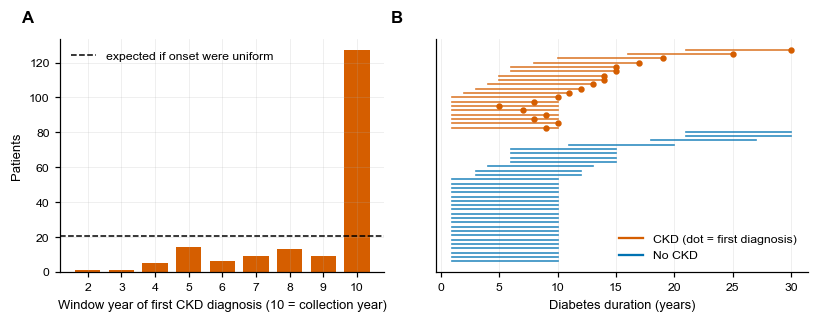

In [7]:
ev = pt[pt.CKD == 1]
cnt = ev["CKD_Year"].astype(int).value_counts().reindex(range(2, 11), fill_value=0).sort_index()
n_ev = int(cnt.sum()); last = int(cnt.loc[10])
lo, hi = wilson(last, n_ev)
p_last = stats.binomtest(last, n_ev, 1 / 9).pvalue                                  # H0: onset uniform over years 2..10
chi_all = stats.chisquare(cnt.values)                                              # uniform over 9 years
chi_rest = stats.chisquare(cnt.loc[2:9].values)                                    # uniform over years 2..9 (the non-spike part)
print(cnt.to_dict())
print(f"first flag in the LAST row: {last}/{n_ev} = {last/n_ev:.1%} (95% CI {lo:.1%}-{hi:.1%}); expected under uniform onset 11.1%; binomial p {fmt_p(p_last)}")
print(f"chi-square uniform over years 2-10: chi2={chi_all.statistic:.1f}, p={fmt_p(chi_all.pvalue)} | uniform over years 2-9 only: chi2={chi_rest.statistic:.1f}, p={fmt_p(chi_rest.pvalue)}")
share_start1 = (pt.YearsDiab_Start == 1).mean()
print(f"window starts at diabetes year 1: {share_start1:.1%} (CKD {(g1.YearsDiab==1).mean():.1%}, no CKD {(g0.YearsDiab==1).mean():.1%})")
record("onset_last_row_n", last); record("onset_last_row_share", last / n_ev); record("onset_last_row_ci", [lo, hi]); record("onset_last_row_binom_p", p_last)
record("onset_rest_uniform_p", chi_rest.pvalue); record("onset_counts", {int(k): int(v) for k, v in cnt.items()})

fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.0), gridspec_kw={"width_ratios": [1, 1.15]})
ax[0].bar(cnt.index, cnt.values, color=C["red"], width=.75); ax[0].axhline(n_ev / 9, color=C["black"], ls="--", lw=1, label="expected if onset were uniform")
ax[0].set(xlabel="Window year of first CKD diagnosis (10 = collection year)", ylabel="Patients", xticks=range(2, 11)); ax[0].legend(loc="upper left"); panel_label(ax[0], "A")
sample = pt.sample(50, random_state=SEED).sort_values(["CKD", "YearsDiab_Start"])
for i, (pid, r) in enumerate(sample.iterrows()):
    col = C["red"] if r.CKD == 1 else C["blue"]; ax[1].plot([r.YearsDiab_Start, r.YearsDiab_Start + 9], [i, i], color=col, lw=1.1, alpha=.8)
    if r.CKD == 1: ax[1].scatter(r.YearsDiab_End, i, color=C["red"], s=10, zorder=3)
ax[1].set(xlabel="Diabetes duration (years)", yticks=[]); ax[1].plot([], [], color=C["red"], label="CKD (dot = first diagnosis)"); ax[1].plot([], [], color=C["blue"], label="No CKD")
ax[1].legend(loc="lower right"); panel_label(ax[1], "B")
fig.tight_layout()
save_fig(fig, 1, "Study design signature",
         "Fig 1. Design signature of the cohort. (A) Window year of the first recorded CKD diagnosis among patients with CKD; the dashed line is the expected count per year if onset were uniform over years 2-10. (B) Observation windows of 50 randomly chosen patients on the diabetes-duration scale; dots mark the first diagnosis.")

**→ Finding.** The first CKD flag falls in the interview year far more often than uniform onset would allow, and the remaining onsets are spread roughly evenly. This is the signature of **recruitment around diagnosis**: it makes the cohort case-enriched, makes "time of onset within the window" partly a sampling artefact, and means **predicted probabilities describe a population resembling this sample** rather than population risk. The consequences are handled in 3.3.

### 1.8 Collinearity
Variance inflation factors (VIF > 5 would be worrying) for the 20 window-start features.

In [8]:
Xv = sm.add_constant(X.astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=[FULL[f] for f in FEAT], name="VIF")
save_table(vif.sort_values(ascending=False).round(2).to_frame(), "TableS1_VIF", "Table S1. Variance inflation factors")
record("vif_max", float(vif.max())); print(f"max VIF = {vif.max():.2f} ({vif.idxmax()})")
vif.sort_values(ascending=False).round(2).head(6).to_frame().T

max VIF = 1.56 (Gender (male))


,Gender (male),Smoking,Age (years),Urinary infection / urological issue,Urinates properly,Takes insulin
VIF,1.56,1.29,1.28,1.25,1.23,1.22


## Part 2 · Primary evaluation (RQ1–RQ3)

### 2.1 Evaluation protocol and models
* **Outer loop:** stratified 5-fold cross-validation repeated `n_repeats` times, **splitting patients** (one row per patient, so no patient is ever in training and test at once).
* **Inner loop:** 3-fold grid search on the training part only, minimising log-loss (a proper scoring rule, so the *probability scale* is tuned as well as the ranking). The test fold never influences any choice (*nested* cross-validation; Cawley & Talbot 2010).
* **Scaling is inside the pipeline**, fitted on training folds only.
* **Pooled out-of-fold (OOF) predictions:** every patient's score comes from models that never saw that patient; predictions are averaged over the repeats. They feed calibration, tiers, lift, decision curves and subgroups.
* **Baselines:** a prevalence-only model (no information) and a model with Age + Diabetes duration only.

Grids are deliberately small: with 400 patients large searches mostly fit noise.

In [9]:
PRIMARY = "Ridge logistic regression (primary)"
SPLITS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=SZ["n_repeats"], random_state=SEED).split(X, y))
N_FOLDS, N_TRAIN, N_TEST = len(SPLITS), len(SPLITS[0][0]), len(SPLITS[0][1]); R_REP = N_FOLDS // 5
INNER = StratifiedKFold(3, shuffle=True, random_state=SEED)

def lr_pipe(penalty="l2"):
    clf = LogisticRegression(max_iter=5000) if penalty == "l2" else LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000)
    return Pipeline([("scale", StandardScaler()), ("clf", clf)])

def zoo():
    return {
      PRIMARY:                      (lr_pipe("l2"), {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
      "Lasso logistic regression":  (lr_pipe("l1"), {"clf__C": [0.03, 0.1, 0.3, 1, 3]}),
      "Random forest":              (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), {"min_samples_leaf": [3, 10], "max_features": ["sqrt", 0.5]}),
      "Gradient boosting (HGB)":    (HistGradientBoostingClassifier(max_iter=150, l2_regularization=1.0, min_samples_leaf=15, random_state=SEED), {"max_depth": [2, 3], "learning_rate": [0.03, 0.08]}),
    }

def nested_cv(name, est, grid, cols=None, splits=None, Xdata=None, ydata=None):
    """Nested CV; returns OOF matrix (repeats x patients) and fold-level metrics."""
    splits = SPLITS if splits is None else splits
    Xc = (X if Xdata is None else Xdata); yc = (y if ydata is None else ydata)
    Xc = Xc if cols is None else Xc[cols]; n = len(yc); R = max(1, len(splits) // 5)
    oof = np.full((R, n), np.nan); rows = []
    for i, (tr, te) in enumerate(splits):
        gs = GridSearchCV(clone(est), grid, cv=INNER, scoring="neg_log_loss", n_jobs=N_JOBS).fit(Xc.iloc[tr], yc.iloc[tr])
        p = gs.predict_proba(Xc.iloc[te])[:, 1]; oof[i // 5, te] = p; yt = yc.iloc[te]
        rows.append(dict(model=name, fold=i, auc=roc_auc_score(yt, p), ap=average_precision_score(yt, p), brier=brier_score_loss(yt, np.clip(p, 1e-9, 1 - 1e-9)),
                         logloss=log_loss(yt, np.clip(p, 1e-9, 1 - 1e-9), labels=[0, 1]), params=str(gs.best_params_)))
    return oof, pd.DataFrame(rows)

OOFS, FOLDS = {}, []
t0 = time.time()
runs = list(zoo().items()) + [("Prevalence only (no information)", (DummyClassifier(strategy="prior"), {"strategy": ["prior"]}), None),
                              ("Age + diabetes duration only", (lr_pipe("l2"), {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}), ["Age", "YearsDiab"])]
for item in runs:
    name, (est, grid) = item[0], item[1] if len(item) == 3 else item[1]
    cols = item[2] if len(item) == 3 else None
    oof, fd = nested_cv(name, est, grid, cols); OOFS[name] = oof; FOLDS.append(fd)
    print(f"{name:38s} fold-mean AUC {fd.auc.mean():.3f} (SD {fd.auc.std():.3f})   [{time.time()-t0:.0f}s]")
FOLDS = pd.concat(FOLDS, ignore_index=True)

Ridge logistic regression (primary)    fold-mean AUC 0.748 (SD 0.047)   [21s]
Lasso logistic regression              fold-mean AUC 0.743 (SD 0.046)   [44s]
Random forest                          fold-mean AUC 0.752 (SD 0.045)   [358s]
Gradient boosting (HGB)                fold-mean AUC 0.753 (SD 0.047)   [459s]
Prevalence only (no information)       fold-mean AUC 0.500 (SD 0.000)   [462s]
Age + diabetes duration only           fold-mean AUC 0.589 (SD 0.057)   [487s]


### 2.2 Primary results: discrimination (Table 2, Fig 2)
Confidence intervals come from a **patient-level percentile bootstrap** of the pooled OOF predictions (`n_boot` resamples). The fold-to-fold SD is shown as well because it reflects training-set variability that the bootstrap does not.

In [10]:
rng = rng_for("bootstrap_auc"); B = SZ["n_boot"]
POOL = {k: v.mean(axis=0) for k, v in OOFS.items()}
order = list(zoo().keys()) + ["Age + diabetes duration only", "Prevalence only (no information)"]
rows, CI = [], {}
for m in order:
    p = POOL[m]; a = roc_auc_score(y, p); lo, hi = boot_ci(y, p, roc_auc_score, B, rng)
    ap = average_precision_score(y, p); aplo, aphi = boot_ci(y, p, average_precision_score, B, rng)
    f = FOLDS[FOLDS.model == m]; CI[m] = (a, lo, hi)
    rows.append({"Model": m, "AUC pooled OOF (95% CI)": ci_str(a, lo, hi), "AUC fold mean ± SD": f"{f.auc.mean():.3f} ± {f.auc.std():.3f}",
                 "PR-AUC (95% CI)": ci_str(ap, aplo, aphi), "Brier": f"{f.brier.mean():.3f}", "Log-loss": f"{f.logloss.mean():.3f}"})
t2 = pd.DataFrame(rows).set_index("Model")
save_table(t2, "Table2_performance", "Table 2. Discrimination and accuracy under nested repeated cross-validation",
           f"{N} patients; outer 5-fold x {SZ['n_repeats']} repeats; 95% CI by patient-level bootstrap ({B} resamples) of pooled out-of-fold predictions; Brier and log-loss are fold means.")
a, lo, hi = CI[PRIMARY]; record("auc_primary", a); record("auc_primary_ci", [lo, hi]); record("auc_primary_fold_sd", FOLDS[FOLDS.model == PRIMARY].auc.std())
for m in order: record(f"auc__{m}", list(CI[m]))
print(f"PRIMARY MODEL AUC = {ci_str(a, lo, hi)}")
t2

PRIMARY MODEL AUC = 0.751 (0.701-0.795)


,AUC pooled OOF (95% CI),AUC fold mean ± SD,PR-AUC (95% CI),Brier,Log-loss
Model,,,,,
Ridge logistic regression (primary),0.751 (0.701-0.795),0.748 ± 0.047,0.724 (0.658-0.788),0.204,0.595
Lasso logistic regression,0.748 (0.699-0.795),0.743 ± 0.046,0.723 (0.658-0.787),0.205,0.597
Random forest,0.762 (0.716-0.808),0.752 ± 0.045,0.732 (0.667-0.793),0.203,0.593
Gradient boosting (HGB),0.764 (0.718-0.810),0.753 ± 0.047,0.731 (0.668-0.791),0.202,0.590
Age + diabetes duration only,0.562 (0.506-0.619),0.589 ± 0.057,0.521 (0.457-0.602),0.245,0.684
Prevalence only (no information),0.500 (0.500-0.500),0.500 ± 0.000,0.463 (0.412-0.510),0.249,0.690


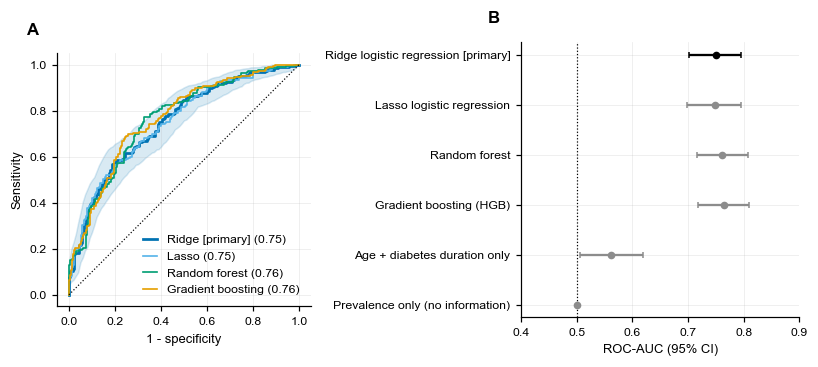

In [11]:
SHORT_MODEL = {PRIMARY: "Ridge [primary]", "Lasso logistic regression": "Lasso", "Random forest": "Random forest", "Gradient boosting (HGB)": "Gradient boosting"}
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.4), gridspec_kw={"width_ratios": [1, 1.1]})
cols = {PRIMARY: C["blue"], "Lasso logistic regression": C["sky"], "Random forest": C["green"], "Gradient boosting (HGB)": C["orange"]}
grid = np.linspace(0, 1, 101); rng = rng_for("roc_band"); tp = []
pp = POOL[PRIMARY]; yy = y.values
for _ in range(min(B, 500)):
    i = rng.integers(0, N, N)
    if len(np.unique(yy[i])) < 2: continue
    f_, t_, _ = roc_curve(yy[i], pp[i]); tp.append(np.interp(grid, f_, t_))
lo_b, hi_b = np.percentile(tp, [2.5, 97.5], axis=0)
for m, c in cols.items():
    f_, t_, _ = roc_curve(y, POOL[m]); ax[0].plot(f_, t_, color=c, lw=1.8 if m == PRIMARY else 1.1, label=f"{SHORT_MODEL[m]} ({CI[m][0]:.2f})")
ax[0].fill_between(grid, lo_b, hi_b, color=C["blue"], alpha=.15); ax[0].plot([0, 1], [0, 1], color=C["black"], ls=":", lw=.8)
ax[0].set(xlabel="1 - specificity", ylabel="Sensitivity", aspect="equal"); ax[0].legend(loc="lower right", fontsize=FS, handlelength=1.2); panel_label(ax[0], "A")
ys = np.arange(len(order))[::-1]
for yv, m in zip(ys, order):
    a_, l_, h_ = CI[m]; ax[1].errorbar(a_, yv, xerr=[[a_ - l_], [h_ - a_]], fmt="o", color=C["black"] if m == PRIMARY else C["grey"], capsize=2, ms=4)
ax[1].axvline(0.5, color=C["black"], ls=":", lw=.8); ax[1].set_yticks(ys); ax[1].set_yticklabels([m.replace(" (primary)", " [primary]") for m in order], fontsize=FS)
ax[1].set(xlabel="ROC-AUC (95% CI)", xlim=(0.4, 0.9)); panel_label(ax[1], "B"); fig.tight_layout()
save_fig(fig, 2, "Discrimination", f"Fig 2. Discrimination under nested repeated cross-validation. (A) ROC curves from pooled out-of-fold predictions (primary model with 95% bootstrap band; AUC in brackets). (B) AUC with 95% patient-level bootstrap confidence intervals for the primary model, comparators and baselines (n = {N}).")

### 2.3 Is the primary model different from its comparators? (paired, with corrected uncertainty)
Differences between models evaluated on the *same* folds are paired, but fold results from repeated CV are correlated (training sets overlap), so the naive standard error is too small. We use the **Nadeau–Bengio corrected resampled t-interval**.

In [12]:
fa = FOLDS[FOLDS.model == PRIMARY].sort_values("fold").auc.values
rows = []
for m in order[1:]:
    fb = FOLDS[FOLDS.model == m].sort_values("fold").auc.values
    d, lo_, hi_, pv = nb_corrected_ci(fa - fb, N_TRAIN, N_TEST); rows.append((m, d, lo_, hi_, pv))
cmp_ = pd.DataFrame(rows, columns=["Comparator", "AUC difference (primary - comparator)", "lo", "hi", "p"])
cmp_["q (FDR)"] = multipletests(cmp_.p, method="fdr_bh")[1]
cmp_out = pd.DataFrame({"Comparator": cmp_.Comparator,
                        "Mean AUC difference (95% CI)": [ci_str(r_[1], r_[2], r_[3]) for r_ in cmp_.itertuples(index=False)],
                        "p": cmp_.p.map(fmt_p), "q (FDR)": cmp_["q (FDR)"].map(fmt_p)}).set_index("Comparator")
save_table(cmp_out, "Table3_model_comparison", "Table 3. Paired comparison of the primary model with comparators",
           "Nadeau-Bengio corrected resampled t-interval over outer folds; positive difference favours the primary model.")
for r_ in cmp_.itertuples(index=False): record(f"diff_vs__{r_.Comparator}", [r_[1], r_[2], r_[3], r_.p])
cmp_out

,Mean AUC difference (95% CI),p,q (FDR)
Comparator,,,
Lasso logistic regression,0.006 (-0.005-0.016),0.276,0.460
Random forest,-0.004 (-0.043-0.035),0.831,0.836
Gradient boosting (HGB),-0.005 (-0.050-0.040),0.836,0.836
Age + diabetes duration only,0.159 (0.082-0.236),<0.001,<0.001
Prevalence only (no information),0.248 (0.199-0.298),<0.001,<0.001



### 2.4 Optimism-corrected performance (Harrell bootstrap)
The *apparent* AUC (model evaluated on the data it was fitted on) is optimistic. The bootstrap estimates that optimism by repeating the **entire modelling strategy**, including tuning, in every resample, and subtracting the average gap between a resample's apparent AUC and its AUC on the original data (Harrell et al., Stat Med 1996). This is the standard internal-validation statistic for a regression model and complements the cross-validation estimate above.

In [13]:
def fit_primary(Xtr, ytr, seed=0):
    est, grid = zoo()[PRIMARY]
    gs = GridSearchCV(clone(est), grid, cv=StratifiedKFold(3, shuffle=True, random_state=seed), scoring="neg_log_loss", n_jobs=1).fit(Xtr, ytr)
    return gs.best_estimator_

full_model = fit_primary(X, y)
C_FULL = full_model.named_steps["clf"].C
apparent = roc_auc_score(y, full_model.predict_proba(X)[:, 1])
rng = rng_for("optimism"); opt = []
for b in range(SZ["n_boot_opt"]):
    i = rng.integers(0, N, N); Xb, yb = X.iloc[i], y.iloc[i]
    if yb.nunique() < 2: continue
    mb = fit_primary(Xb, yb, seed=b)
    opt.append(roc_auc_score(yb, mb.predict_proba(Xb)[:, 1]) - roc_auc_score(y, mb.predict_proba(X)[:, 1]))
opt_mean = float(np.mean(opt)); corrected = apparent - opt_mean
print(f"final model C = {C_FULL} | apparent AUC {apparent:.3f} | mean optimism {opt_mean:.3f} | optimism-corrected AUC {corrected:.3f}")
record("auc_apparent", apparent); record("auc_optimism", opt_mean); record("auc_optimism_corrected", corrected); record("C_final", C_FULL)

final model C = 0.1 | apparent AUC 0.800 | mean optimism 0.043 | optimism-corrected AUC 0.757


### 2.5 Is there real signal? Label-permutation test
Shuffling the outcome labels destroys any true relationship. Repeating cross-validation on shuffled labels gives the AUC distribution **under no signal**; the p-value is `(1 + #(null ≥ observed)) / (1 + n_perm)`.

In [14]:
def cv_auc_fixed(Xd, yd, C, seed, k=5):
    m = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=C, max_iter=5000))])
    a = []
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=seed).split(Xd, yd):
        a.append(roc_auc_score(yd.iloc[te], clone(m).fit(Xd.iloc[tr], yd.iloc[tr]).predict_proba(Xd.iloc[te])[:, 1]))
    return float(np.mean(a))
rng = rng_for("permutation")
obs = float(np.mean([cv_auc_fixed(X, y, C_FULL, s) for s in range(3)]))
null = np.array([cv_auc_fixed(X, pd.Series(rng.permutation(y.values), index=y.index), C_FULL, int(rng.integers(1e6))) for _ in range(SZ["n_perm"])])
p_perm = (1 + (null >= obs).sum()) / (1 + SZ["n_perm"])
print(f"observed CV AUC {obs:.3f} | null mean {null.mean():.3f} (SD {null.std():.3f}, max {null.max():.3f}) | permutation p = {p_perm:.4f}")
record("perm_obs_auc", obs); record("perm_null_mean", null.mean()); record("perm_null_sd", null.std()); record("perm_null_max", null.max()); record("perm_p", p_perm)

observed CV AUC 0.747 | null mean 0.502 (SD 0.041, max 0.627) | permutation p = 0.0020


### 2.6 Sample-size adequacy (Riley et al. 2020)
Riley and colleagues give four minimum-sample-size criteria that depend on the number of candidate predictor parameters (*p*), the outcome prevalence (φ) and the anticipated model fit (Cox–Snell R²). We evaluate them **retrospectively**, using the cross-validated R² of the primary model as a deliberately conservative anticipated value:

1. small overfitting: expected shrinkage ≥ 0.90;
2. small optimism in apparent fit (δ = 0.05 on the Nagelkerke R² scale);
3. precise estimate of the overall risk (margin of error ±0.05);
4. *(events per variable is reported only for orientation: single EPV rules are no longer recommended.)*

> Formulas follow Riley RD et al., BMJ 2020;368:m441. They were implemented from the paper and verified against the `pmsampsize` package (criteria 1-3 agree to within one patient at R² = 0.182, 20 parameters, prevalence 0.4625).

In [15]:
def riley_n(p, phi, r2cs_adj, S=0.90, delta=0.05, moe=0.05):
    n1 = p / ((S - 1) * math.log(1 - r2cs_adj / S))
    max_r2 = 1 - math.exp(2 * (phi * math.log(phi) + (1 - phi) * math.log(1 - phi)))
    s_vh = r2cs_adj / (r2cs_adj + delta * max_r2)
    n2 = p / ((s_vh - 1) * math.log(1 - r2cs_adj / s_vh))
    n3 = (1.96 / moe) ** 2 * phi * (1 - phi)
    return n1, n2, n3, max_r2

p_oof_primary = POOL[PRIMARY]
ll_cv = -N * log_loss(y, np.clip(p_oof_primary, 1e-9, 1 - 1e-9)); ll_null = N * (prev * math.log(prev) + (1 - prev) * math.log(1 - prev))
r2cs_cv = max(1 - math.exp(2 * (ll_null - ll_cv) / N), 1e-4)
n1, n2, n3, max_r2 = riley_n(P, prev, r2cs_cv)
req = max(n1, n2, n3)
ss = pd.DataFrame({"Criterion": ["1. Shrinkage >= 0.90", "2. Optimism in Nagelkerke R2 <= 0.05", "3. Overall risk within +/-0.05", "Required (maximum)", "Available"],
                   "Minimum n": [round(n1), round(n2), round(n3), round(req), N],
                   "Available / required": [N / n1, N / n2, N / n3, N / req, 1.0]}).set_index("Criterion")
ss["Available / required"] = ss["Available / required"].map(lambda v: f"{v:.2f}")
save_table(ss, "Table4_sample_size", "Table 4. Retrospective sample-size adequacy (Riley et al. criteria)",
           f"p = {P} candidate parameters; prevalence {prev:.3f}; anticipated Cox-Snell R2 = {r2cs_cv:.3f} (cross-validated); EPV = {int(y.sum())}/{P} = {y.sum()/P:.1f}.")
record("riley_r2cs_cv", r2cs_cv); record("riley_n_shrinkage", n1); record("riley_n_optimism", n2); record("riley_n_precision", n3); record("riley_required", req); record("epv", y.sum() / P)
print(f"cross-validated Cox-Snell R2 = {r2cs_cv:.3f}; EPV = {y.sum()/P:.2f}")
ss

cross-validated Cox-Snell R2 = 0.182; EPV = 9.25


,Minimum n,Available / required
Criterion,,
1. Shrinkage >= 0.90,883,0.45
2. Optimism in Nagelkerke R2 <= 0.05,473,0.85
3. Overall risk within +/-0.05,382,1.05
Required (maximum),883,0.45
Available,400,1.00


**→ Finding.** The cohort is **smaller than the recommended minimum for developing a definitive 20-parameter model with low overfitting risk**. That is not hidden here: it is why the study (i) uses a penalised model, (ii) reports uncertainty everywhere, (iii) frames its claims as modest and internally validated, and (iv) devotes RQ7 to what this sample size implies for evaluation reliability.

### 2.7 Calibration, risk groups, testing-prioritisation and decision curve (Fig 3)
* **Calibration** (TRIPOD+AI: assess graphically): observed CKD frequency against predicted probability, with a smooth LOWESS curve and quantile-bin points with Wilson intervals; calibration **slope** (1 = ideal; < 1 over-confident) and **calibration-in-the-large** (0 = ideal), with bootstrap intervals.
* **Risk groups:** tertiles of the OOF score, with the *observed* CKD proportion in each (a statement about real patients).
* **Testing prioritisation (lift):** if a clinic can test only the top *k*% by score, what share of CKD patients does it catch, compared with testing *k*% at random?
* **Decision curve** (Vickers & Elkin 2006): net benefit = TP/n − FP/n · t/(1 − t) against "test everyone" and "test no one".

> All of this is relative to the **case-enriched sample** (prevalence 46%). S3.3 shows what that implies for absolute probabilities.

calibration slope 1.06 (0.79-1.33) | calibration-in-the-large -0.00 (-0.23-0.21) | Brier 0.202 (prevalence-only 0.249)


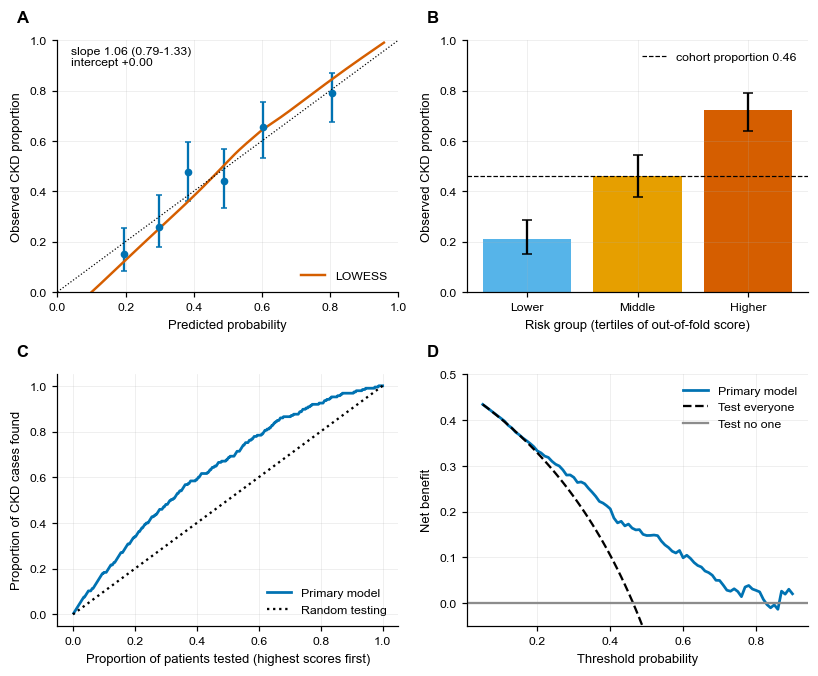

,Patients,CKD cases,Mean predicted risk,Observed CKD proportion (95% CI)
tier,,,,
Lower,134,28,0.247,0.209 (0.149-0.285)
Middle,133,61,0.437,0.459 (0.376-0.543)
Higher,133,96,0.706,0.722 (0.640-0.791)


,"CKD cases caught (sensitivity, 95% CI)",CKD proportion among tested (PPV),Lift vs random testing
Tested (top % by score),,,
10%,0.18 (0.15-0.21),0.85,1.84
20%,0.34 (0.30-0.38),0.79,1.70
30%,0.48 (0.43-0.53),0.74,1.60
40%,0.59 (0.55-0.65),0.68,1.47
50%,0.68 (0.63-0.74),0.63,1.36
60%,0.78 (0.73-0.84),0.60,1.31


In [16]:
pp = POOL[PRIMARY]; yy = y.values; rng = rng_for("calibration")
slope, citl = calib_stats(yy, pp)
bs = []
for _ in range(min(B, 1000)):
    i = rng.integers(0, N, N)
    if len(np.unique(yy[i])) == 2: bs.append(calib_stats(yy[i], pp[i]))
bs = np.array(bs); slope_ci = np.percentile(bs[:, 0], [2.5, 97.5]); citl_ci = np.percentile(bs[:, 1], [2.5, 97.5])
brier = brier_score_loss(yy, pp); brier_ref = prev * (1 - prev)
print(f"calibration slope {ci_str(slope, *slope_ci, d=2)} | calibration-in-the-large {ci_str(citl, *citl_ci, d=2)} | Brier {brier:.3f} (prevalence-only {brier_ref:.3f})")
record("calib_slope", slope); record("calib_slope_ci", slope_ci); record("calib_citl", citl); record("calib_citl_ci", citl_ci); record("brier_primary", brier); record("brier_null", brier_ref)

# risk groups (tertiles of OOF score)
cuts = np.quantile(pp, [1 / 3, 2 / 3]); tier = pd.cut(pp, [-np.inf, cuts[0], cuts[1], np.inf], labels=["Lower", "Middle", "Higher"])
tg = pd.DataFrame({"tier": tier, "y": yy, "p": pp}).groupby("tier", observed=True).agg(n=("y", "size"), cases=("y", "sum"), mean_pred=("p", "mean"))
tg["observed"] = tg.cases / tg.n; tg[["lo", "hi"]] = [wilson(c_, n_) for c_, n_ in zip(tg.cases, tg.n)]
tier_tab = pd.DataFrame({"Patients": tg.n, "CKD cases": tg.cases, "Mean predicted risk": tg.mean_pred.round(3),
                         "Observed CKD proportion (95% CI)": [ci_str(r_.observed, r_.lo, r_.hi) for r_ in tg.itertuples()]})
save_table(tier_tab, "Table5_risk_groups", "Table 5. Observed CKD proportion by risk group (tertiles of the out-of-fold score)")
record("tier_observed", {k: float(v) for k, v in tg.observed.items()}); record("tier_cuts", cuts)

# testing prioritisation (lift)
ordr = np.argsort(-pp); ys_sorted = yy[ordr]; rows = []
rng2 = rng_for("lift")
def sens_at(yv, pv, frac):
    o = np.argsort(-pv); k = int(round(len(yv) * frac)); return yv[o][:k].sum() / yv.sum()
for frac in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    k = int(round(N * frac)); sens = ys_sorted[:k].sum() / yy.sum(); ppv = ys_sorted[:k].mean()
    bl = []
    for _ in range(min(B, 1000)):
        i = rng2.integers(0, N, N)
        if yy[i].sum() > 0: bl.append(sens_at(yy[i], pp[i], frac))
    lo_, hi_ = np.percentile(bl, [2.5, 97.5])
    rows.append((f"{int(frac*100)}%", ci_str(sens, lo_, hi_, 2), f"{ppv:.2f}", f"{sens/frac:.2f}"))
lift = pd.DataFrame(rows, columns=["Tested (top % by score)", "CKD cases caught (sensitivity, 95% CI)", "CKD proportion among tested (PPV)", "Lift vs random testing"]).set_index("Tested (top % by score)")
save_table(lift, "Table6_lift", "Table 6. Testing-prioritisation scenario", "Share of CKD cases found when only the top k% by score are tested.")
record("lift_table", lift.reset_index().to_dict("records"))

# decision curve
ts = np.linspace(0.05, 0.90, 86); nb_m = np.array([net_benefit(yy, pp, t) for t in ts]); nb_all = prev - (1 - prev) * ts / (1 - ts)
dca_rows = [(t, net_benefit(yy, pp, t), prev - (1 - prev) * t / (1 - t)) for t in (0.3, 0.4, 0.5, 0.6)]
dca_tab = pd.DataFrame(dca_rows, columns=["Threshold", "Net benefit model", "Net benefit test-all"]).round(3).set_index("Threshold")
save_table(dca_tab, "Table7_decision_curve", "Table 7. Net benefit at selected thresholds"); record("dca", dca_tab.reset_index().to_dict("records"))

fig, ax = plt.subplots(2, 2, figsize=(7.5, 6.2)); a_ = ax.ravel()
fr, mp = calibration_curve(yy, pp, n_bins=6, strategy="quantile"); counts = np.array_split(np.argsort(pp), 6)
for (idx, f_, m_) in zip(counts, fr, mp):
    lo_, hi_ = wilson(int(yy[idx].sum()), len(idx)); a_[0].errorbar(m_, f_, yerr=[[f_ - lo_], [hi_ - f_]], fmt="o", color=C["blue"], capsize=2, ms=4)
lw = lowess(yy, pp, frac=0.75); a_[0].plot(lw[:, 0], lw[:, 1], color=C["red"], lw=1.6, label="LOWESS")
a_[0].plot([0, 1], [0, 1], color=C["black"], ls=":", lw=.8); a_[0].set(xlabel="Predicted probability", ylabel="Observed CKD proportion", xlim=(0, 1), ylim=(0, 1))
a_[0].text(.04, .9, f"slope {slope:.2f} ({slope_ci[0]:.2f}-{slope_ci[1]:.2f})\nintercept {(0.0 if abs(citl) < 0.005 else citl):+.2f}", fontsize=FS); a_[0].legend(loc="lower right"); panel_label(a_[0], "A")
a_[1].bar(tier_tab.index, tg.observed, color=[C["sky"], C["orange"], C["red"]], yerr=[tg.observed - tg.lo, tg.hi - tg.observed], capsize=3)
a_[1].axhline(prev, color=C["black"], ls="--", lw=.8, label=f"cohort proportion {prev:.2f}"); a_[1].set(ylabel="Observed CKD proportion", xlabel="Risk group (tertiles of out-of-fold score)", ylim=(0, 1)); a_[1].legend(); panel_label(a_[1], "B")
xs = np.arange(1, N + 1) / N; a_[2].plot(xs, np.cumsum(ys_sorted) / yy.sum(), color=C["blue"], lw=1.8, label="Primary model"); a_[2].plot([0, 1], [0, 1], color=C["black"], ls=":", label="Random testing")
a_[2].set(xlabel="Proportion of patients tested (highest scores first)", ylabel="Proportion of CKD cases found"); a_[2].legend(loc="lower right"); panel_label(a_[2], "C")
a_[3].plot(ts, nb_m, color=C["blue"], lw=1.8, label="Primary model"); a_[3].plot(ts, nb_all, color=C["black"], ls="--", label="Test everyone"); a_[3].axhline(0, color=C["grey"], label="Test no one")
a_[3].set(xlabel="Threshold probability", ylabel="Net benefit", ylim=(-0.05, 0.5)); a_[3].legend(); panel_label(a_[3], "D"); fig.tight_layout()
save_fig(fig, 3, "Calibration and clinical utility", "Fig 3. Calibration and clinical utility of the primary model (pooled out-of-fold predictions). (A) Calibration plot with LOWESS curve and quantile-bin proportions (95% Wilson intervals). (B) Observed CKD proportion in tertile risk groups. (C) Cumulative gains: proportion of CKD cases found when testing the highest-scored patients first. (D) Decision curve analysis. All probabilities refer to a sample with 46% CKD prevalence.")
display(tier_tab); display(lift)

### 2.8 Subgroup performance (TRIPOD+AI: evaluate in key subgroups)
AUC and calibration (observed/expected ratio) within gender, age, BMI and diabetes-duration subgroups, from the OOF predictions. With 400 patients the subgroup intervals are wide: the purpose is to look for **large gaps**, not to certify equality.

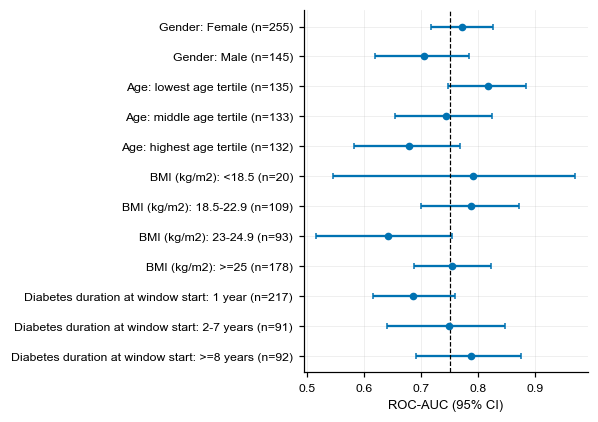

n  CKD proportion  \
Subgroup                          Level                                      
Gender                            Female               255           0.435   
                                  Male                 145           0.510   
Age                               lowest age tertile   135           0.489   
                                  middle age tertile   133           0.436   
                                  highest age tertile  132           0.462   
BMI (kg/m2)                       <18.5                 20           0.350   
                                  18.5-22.9            109           0.358   
                                  23-24.9               93           0.441   
                                  >=25                 178           0.551   
Diabetes duration at window start 1 year               217           0.346   
                                  2-7 years             91           0.582   
                                  >=8 years             92           0.620   

                                                           AUC (95% CI)  \
Subgroup                          Level                                   
Gender                            Female               0.77 (0.72-0.83)   
                                  Male                 0.70 (0.62-0.78)   
Age                               lowest age tertile   0.82 (0.75-0.88)   
                                  middle age tertile   0.74 (0.66-0.82)   
                                  highest age tertile  0.68 (0.58-0.77)   
BMI (kg/m2)                       <18.5                0.79 (0.55-0.97)   
                                  18.5-22.9            0.79 (0.70-0.87)   
                                  23-24.9              0.64 (0.52-0.75)   
                                  >=25                 0.75 (0.69-0.82)   
Diabetes duration at window start 1 year               0.69 (0.61-0.76)   
                                  2-7 years            0.75 (0.64-0.85)   
                                  >=8 years            0.79 (0.69-0.88)   

                                                       Observed/expected  
Subgroup                          Level                                   
Gender                            Female                            0.98  
                                  Male                              1.02  
Age                               lowest age tertile                1.05  
                                  middle age tertile                0.93  
                                  highest age tertile               1.02  
BMI (kg/m2)                       <18.5                             0.97  
                                  18.5-22.9                         0.88  
                                  23-24.9                           0.97  
                                  >=25                              1.07  
Diabetes duration at window start 1 year                            0.86  
                                  2-7 years                         1.18  
                                  >=8 years                         1.08

In [17]:
bmi_cat = pd.cut(pt.BMI, [0, 18.5, 23, 25, 100], right=False, labels=["<18.5", "18.5-22.9", "23-24.9", ">=25"])
age_cat = pd.qcut(pt.Age, 3, labels=["lowest age tertile", "middle age tertile", "highest age tertile"])
dy_cat = pd.cut(pt.YearsDiab, [0, 2, 8, 100], right=False, labels=["1 year", "2-7 years", ">=8 years"])
groups = {"Gender": pd.Series(np.where(pt.Gender == 1, "Male", "Female"), index=pt.index), "Age": age_cat, "BMI (kg/m2)": bmi_cat, "Diabetes duration at window start": dy_cat}
rng = rng_for("subgroups"); rows = []
for gname, lab in groups.items():
    levels = list(lab.cat.categories) if hasattr(lab, "cat") else sorted(pd.Series(lab).dropna().unique())
    for lv in levels:
        m_ = (pd.Series(lab, index=pt.index) == lv).values
        if m_.sum() < 20 or len(np.unique(yy[m_])) < 2: continue
        a_ = roc_auc_score(yy[m_], pp[m_]); lo_, hi_ = boot_ci(yy[m_], pp[m_], roc_auc_score, min(B, 1000), rng)
        rows.append(dict(Subgroup=gname, Level=str(lv), n=int(m_.sum()), CKD_prop=yy[m_].mean(), AUC=a_, lo=lo_, hi=hi_, OE=yy[m_].mean() / pp[m_].mean()))
sg = pd.DataFrame(rows)
sg_out = pd.DataFrame({"Subgroup": sg.Subgroup, "Level": sg.Level, "n": sg.n, "CKD proportion": sg.CKD_prop.round(3), "AUC (95% CI)": [ci_str(r_.AUC, r_.lo, r_.hi, 2) for r_ in sg.itertuples()],
                       "Observed/expected": sg.OE.round(2)}).set_index(["Subgroup", "Level"])
save_table(sg_out, "TableS2_subgroups", "Table S2. Discrimination and calibration by subgroup")
record("subgroup_auc_range", [float(sg.AUC.min()), float(sg.AUC.max())])
fig, ax = plt.subplots(figsize=(5.5, 3.9)); yv = np.arange(len(sg))[::-1]
ax.errorbar(sg.AUC, yv, xerr=[sg.AUC - sg.lo, sg.hi - sg.AUC], fmt="o", color=C["blue"], capsize=2, ms=4); ax.axvline(CI[PRIMARY][0], color=C["black"], ls="--", lw=.8)
ax.set_yticks(yv); ax.set_yticklabels([f"{r_.Subgroup}: {r_.Level} (n={r_.n})" for r_ in sg.itertuples()], fontsize=FS); ax.set(xlabel="ROC-AUC (95% CI)"); fig.tight_layout()
save_fig(fig, "S1", "Subgroup performance", "S1 Fig. Discrimination of the primary model within subgroups (pooled out-of-fold predictions; 95% bootstrap intervals). Dashed line: overall AUC.")
sg_out

### 2.9 Which features carry information, and do the effects make clinical sense? (Fig 4)
Three complementary views, none of which is causal:

1. **Ridge coefficients as odds ratios per 1 SD** (binary features per SD of the 0/1 variable, so all effects share one scale), with **bootstrap intervals and sign agreement**. A narrow, stable interval means the data support the direction.
2. **Permutation importance** on held-out folds: how much the AUC falls when one feature is shuffled.
3. **Plausibility audit:** the sign of each supported effect against clinical expectation (registry above). A contradiction is not an error but a warning that the association may reflect reverse causation, selection or measurement.

The unpenalised regression table with p-values (Supplement) is provided for readers who need inference on individual coefficients.

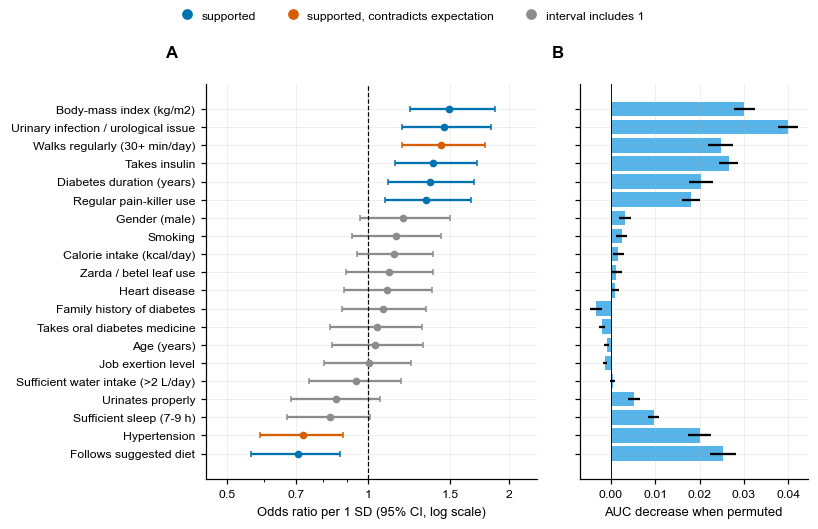

,OR per SD (95% bootstrap CI),Sign agreement,Permutation importance (AUC drop),Clinical-plausibility audit
Feature,,,,
Follows suggested diet,0.71 (0.56-0.87),100%,0.025,supported and consistent with expectation
Hypertension,0.73 (0.59-0.88),100%,0.020,supported but CONTRADICTS expectation
Sufficient sleep (7-9 h),0.83 (0.67-1.01),97%,0.010,interval includes 1 (not supported)
Urinates properly,0.85 (0.69-1.06),92%,0.005,interval includes 1 (not supported)
Sufficient water intake (>2 L/day),0.94 (0.75-1.18),71%,0.000,interval includes 1 (not supported)
Job exertion level,1.00 (0.80-1.24),50%,-0.001,interval includes 1 (not supported)
Age (years),1.03 (0.84-1.31),62%,-0.001,interval includes 1 (not supported)
Takes oral diabetes medicine,1.05 (0.83-1.30),65%,-0.002,interval includes 1 (not supported)
Family history of diabetes,1.07 (0.88-1.33),78%,-0.003,interval includes 1 (not supported)


In [18]:
mu, sd = X.mean(), X.std(ddof=0)
final_ridge = clone(zoo()[PRIMARY][0]).set_params(clf__C=C_FULL).fit(X, y)
beta = final_ridge.named_steps["clf"].coef_[0]
rng = rng_for("coef_boot"); bb = []
for _ in range(SZ["n_boot"]):
    i = rng.integers(0, N, N)
    if y.iloc[i].nunique() < 2: continue
    bb.append(clone(zoo()[PRIMARY][0]).set_params(clf__C=C_FULL).fit(X.iloc[i], y.iloc[i]).named_steps["clf"].coef_[0])
bb = np.array(bb)
coef = pd.DataFrame({"feature": FEAT, "OR_per_SD": np.exp(beta), "lo": np.exp(np.percentile(bb, 2.5, axis=0)), "hi": np.exp(np.percentile(bb, 97.5, axis=0)),
                     "sign_agreement": [(np.sign(bb[:, j]) == np.sign(beta[j])).mean() for j in range(P)]}).set_index("feature")
coef["expected"] = REGISTRY.expected
def verdict(r_):
    if r_.lo <= 1 <= r_.hi: return "interval includes 1 (not supported)"
    if r_.expected == 0: return "supported; no prior expectation"
    return "supported and consistent with expectation" if np.sign(np.log(r_.OR_per_SD)) == r_.expected else "supported but CONTRADICTS expectation"
coef["audit"] = coef.apply(verdict, axis=1)

# permutation importance on held-out folds
rng3 = rng_for("perm_importance"); drops = np.zeros((N_FOLDS, P))
for i, (tr, te) in enumerate(SPLITS):
    m_ = clone(zoo()[PRIMARY][0]).set_params(clf__C=C_FULL).fit(X.iloc[tr], y.iloc[tr])
    pi = permutation_importance(m_, X.iloc[te], y.iloc[te], scoring="roc_auc", n_repeats=5, random_state=int(rng3.integers(1e6)))
    drops[i] = pi.importances_mean
coef["perm_importance"] = drops.mean(axis=0); coef["perm_importance_sd"] = drops.std(axis=0)

ct = coef.sort_values("OR_per_SD")
coef_out = pd.DataFrame({"Feature": [FULL[f] for f in ct.index], "OR per SD (95% bootstrap CI)": [ci_str(r_.OR_per_SD, r_.lo, r_.hi, 2) for r_ in ct.itertuples()],
                         "Sign agreement": ct.sign_agreement.map(lambda v: f"{v:.0%}"), "Permutation importance (AUC drop)": ct.perm_importance.round(3), "Clinical-plausibility audit": ct.audit}).set_index("Feature")
save_table(coef_out, "Table8_feature_evidence", "Table 8. Feature evidence from the ridge model", f"Ridge C = {C_FULL}; {SZ['n_boot']} bootstrap resamples; permutation importance over {N_FOLDS} held-out folds.")
record("features_contradicting", [FULL[f] for f in coef.index[coef.audit.str.contains("CONTRADICTS")]])
record("features_supported", [FULL[f] for f in coef.index[~coef.audit.str.startswith("interval")]]); record("coef_table", coef.round(4).reset_index().to_dict("records"))

fig, ax = plt.subplots(1, 2, figsize=(7.5, 4.8), sharey=True, gridspec_kw={"width_ratios": [1.45, 1]}); yv = np.arange(P)
colmap = lambda a: C["red"] if "CONTRADICTS" in a else (C["blue"] if a.startswith("supported") else C["grey"])
for yi, (f, r_) in zip(yv, ct.iterrows()):
    ax[0].errorbar(r_.OR_per_SD, yi, xerr=[[r_.OR_per_SD - r_.lo], [r_.hi - r_.OR_per_SD]], fmt="o", color=colmap(r_.audit), capsize=2, ms=4)
ax[0].axvline(1, color=C["black"], ls="--", lw=.8); ax[0].set_xscale("log"); ax[0].set_yticks(yv); ax[0].set_yticklabels([FULL[f] for f in ct.index], fontsize=FS)
ax[0].set_xticks([0.5, 0.7, 1, 1.5, 2]); ax[0].xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g")); ax[0].xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax[0].set(xlabel="Odds ratio per 1 SD (95% CI, log scale)", xlim=(0.45, 2.3)); panel_label(ax[0], "A")
ax[0].plot([], [], "o", color=C["blue"], label="supported"); ax[0].plot([], [], "o", color=C["red"], label="supported, contradicts expectation"); ax[0].plot([], [], "o", color=C["grey"], label="interval includes 1");
ax[1].barh(yv, ct.perm_importance, xerr=ct.perm_importance_sd / np.sqrt(N_FOLDS), color=C["sky"])   # same feature order as panel A
ax[1].axvline(0, color=C["black"], lw=.6); ax[1].tick_params(axis="y", labelleft=False); ax[1].set(xlabel="AUC decrease when permuted"); panel_label(ax[1], "B")
fig.legend(*ax[0].get_legend_handles_labels(), loc="upper center", ncol=3, fontsize=FS, frameon=False, handletextpad=0.2); fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, 4, "Feature evidence", "Fig 4. Feature evidence. (A) Odds ratio per 1 SD from the ridge model with 95% bootstrap intervals, coloured by the clinical-plausibility audit. (B) Permutation importance on held-out folds (mean AUC decrease; error bars: standard error over folds), features in the same order as panel A. Associations are not causal.")
# Full model specification (TRIPOD+AI item 22): the fitted equation on the standardised and on the original scale
sc_ = final_ridge.named_steps["scale"]; clf_ = final_ridge.named_steps["clf"]
b_std = clf_.coef_[0]; b0_std = float(clf_.intercept_[0]); b_raw = b_std / sc_.scale_; b0_raw = b0_std - float(np.sum(b_std * sc_.mean_ / sc_.scale_))
spec = pd.DataFrame({"Predictor": ["Intercept"] + [FULL[f] for f in FEAT], "Coding": ["-"] + [REGISTRY.loc[f, "coding"] for f in FEAT],
                     "Mean (centring)": [np.nan] + list(sc_.mean_), "SD (scaling)": [np.nan] + list(sc_.scale_),
                     "Coefficient, standardised predictor": [b0_std] + list(b_std), "Coefficient, original units": [b0_raw] + list(b_raw)})
save_table(spec.round(5).set_index("Predictor"), "TableS6_model_specification", "Table S6. Final ridge logistic regression model (full specification)",
           f"Fitted to all {N} patients, C = {C_FULL}. Predicted probability = 1 / (1 + exp(-(intercept + sum of coefficient x predictor))), using either the standardised or the original-unit coefficients. Probabilities refer to a sample with {prev:.0%} CKD prevalence.")
record("model_intercept_std", b0_std); record("model_intercept_raw", b0_raw)
coef_out



### 2.10 Regression table for the supplement (unpenalised logistic regression)
Full coefficients, standard errors, p-values and confidence intervals, as PLOS ONE requests for regression analyses. Continuous variables are reported per natural unit and per SD. p-values are FDR-adjusted.

In [19]:
Xs = (X - mu) / sd
fit_sm = sm.Logit(y, sm.add_constant(Xs)).fit(disp=0)
fit_nat = sm.Logit(y, sm.add_constant(X)).fit(disp=0)
reg = pd.DataFrame({"Feature": [FULL[f] for f in FEAT], "Coefficient (per unit)": fit_nat.params[FEAT].values, "SE": fit_nat.bse[FEAT].values,
                    "OR per unit": np.exp(fit_nat.params[FEAT].values), "OR lo": np.exp(fit_nat.conf_int().loc[FEAT, 0].values), "OR hi": np.exp(fit_nat.conf_int().loc[FEAT, 1].values),
                    "OR per SD": np.exp(fit_sm.params[FEAT].values), "p": fit_nat.pvalues[FEAT].values})
reg["q (FDR)"] = multipletests(reg.p, method="fdr_bh")[1]; reg["Pseudo R2 (McFadden)"] = fit_nat.prsquared
reg_o = reg.copy(); reg_o["p"] = reg.p.map(fmt_p); reg_o["q (FDR)"] = reg["q (FDR)"].map(fmt_p)
save_table(reg_o.round(3).set_index("Feature"), "TableS3_logistic_regression", "Table S3. Unpenalised multivariable logistic regression (n = 400)")
record("n_p_lt_005_unpenalised", int((reg.p < 0.05).sum())); record("n_q_lt_005_unpenalised", int((reg["q (FDR)"] < 0.05).sum()))
reg_o.round(3).set_index("Feature").head(20)

,Coefficient (per unit),SE,OR per unit,OR lo,OR hi,OR per SD,p,q (FDR),Pseudo R2 (McFadden)
Feature,,,,,,,,,
Gender (male),0.453,0.308,1.573,0.860,2.880,1.243,0.142,0.283,0.217
Job exertion level,-0.020,0.207,0.980,0.653,1.471,0.988,0.923,0.923,0.217
Family history of diabetes,0.162,0.246,1.176,0.727,1.903,1.083,0.509,0.615,0.217
Diabetes duration (years),0.062,0.022,1.064,1.018,1.111,1.433,0.006,0.016,0.217
Age (years),0.003,0.013,1.003,0.979,1.028,1.031,0.818,0.861,0.217
Body-mass index (kg/m2),0.130,0.035,1.138,1.063,1.219,1.631,<0.001,0.004,0.217
Follows suggested diet,-1.113,0.348,0.329,0.166,0.651,0.655,0.001,0.007,0.217
Takes oral diabetes medicine,0.189,0.306,1.208,0.663,2.199,1.085,0.537,0.615,0.217
Takes insulin,0.765,0.263,2.148,1.283,3.598,1.461,0.004,0.012,0.217


### 2.11 Sensitivity analyses
| Analysis | Why |
|---|---|
| **Outliers** removed (Tukey 1.5×IQR on Age, diabetes duration, BMI, calorie intake) | results with and without outliers |
| **Non-linearity**: spline terms for the four continuous features | checks the linearity assumption of the regression |
| **Different random seed** for the whole nested CV | shows the conclusion does not depend on one shuffle |
| **Feature-group ablation** (alone / leave-group-out) | which clinical domains carry information; fixed-C ridge, same folds |

In [20]:
# (1) outliers
flag = pd.Series(False, index=pt.index); out_rows = []
for f in ["Age", "YearsDiab", "BMI", "CalIntake"]:
    q1, q3 = X[f].quantile([.25, .75]); iqr = q3 - q1; m_ = (X[f] < q1 - 1.5 * iqr) | (X[f] > q3 + 1.5 * iqr); flag |= m_; out_rows.append((FULL[f], int(m_.sum())))
keep = ~flag; est, grid = zoo()[PRIMARY]
sp_o = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=max(2, SZ["n_repeats"] // 2), random_state=SEED).split(X[keep], y[keep]))
oof_o, f_o = nested_cv(PRIMARY, est, grid, splits=sp_o, Xdata=X[keep].reset_index(drop=True), ydata=y[keep].reset_index(drop=True))
auc_out = roc_auc_score(y[keep].values, oof_o.mean(axis=0))
# (2) non-linearity (splines on continuous features)
from sklearn.compose import ColumnTransformer
spl = Pipeline([("ct", ColumnTransformer([("spl", SplineTransformer(n_knots=4, degree=3), CONT)], remainder="passthrough")), ("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))])
oof_s, f_s = nested_cv("Ridge + splines", spl, {"clf__C": [0.01, 0.03, 0.1, 0.3, 1]})
auc_spl = roc_auc_score(y, oof_s.mean(axis=0)); d_s = nb_corrected_ci(FOLDS[FOLDS.model == PRIMARY].sort_values("fold").auc.values - f_s.sort_values("fold").auc.values, N_TRAIN, N_TEST)
# (3) alternative seed
sp_alt = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=SZ["n_repeats"], random_state=SEED + 1).split(X, y))
oof_a, f_a = nested_cv(PRIMARY, est, grid, splits=sp_alt); auc_alt = roc_auc_score(y, oof_a.mean(axis=0))
sens = pd.DataFrame([
   ("Primary analysis (all 400 patients)", N, CI[PRIMARY][0]),
   (f"Outlier-flagged patients removed (n = {int(flag.sum())} flagged)", int(keep.sum()), auc_out),
   ("Spline terms for continuous features", N, auc_spl),
   ("Alternative random seed for nested CV", N, auc_alt)], columns=["Analysis", "n", "AUC (pooled OOF)"])
sens["AUC (pooled OOF)"] = sens["AUC (pooled OOF)"].round(3)
save_table(sens.set_index("Analysis"), "TableS4_sensitivity", "Table S4. Sensitivity analyses", f"Outlier counts by variable: {dict(out_rows)}; spline minus primary AUC difference {-d_s[0]:+.3f} (NB 95% CI {-d_s[2]:+.3f} to {-d_s[1]:+.3f}).")
record("sens_outlier_auc", auc_out); record("sens_outlier_flagged", int(flag.sum())); record("sens_spline_auc", auc_spl); record("sens_spline_diff", list(d_s)); record("sens_alt_seed_auc", auc_alt)

# (4) feature-group ablation
GROUPS = {"Demographics and body": ["Gender", "Age", "BMI", "Job", "FamHist"], "Diabetes history and treatment": ["YearsDiab", "Diet", "Meds", "Insulin"],
          "Comorbidity, urinary and medication": ["Hypertension", "HeartDis", "Infect", "Urinate", "Painkiller"], "Lifestyle and substances": ["Sleep", "Water", "Smoke", "Zarda", "Walk", "CalIntake"]}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEAT)
def fold_aucs(cols):
    out = []
    for tr, te in SPLITS:
        m_ = clone(zoo()[PRIMARY][0]).set_params(clf__C=C_FULL).fit(X.iloc[tr][cols], y.iloc[tr]); out.append(roc_auc_score(y.iloc[te], m_.predict_proba(X.iloc[te][cols])[:, 1]))
    return np.array(out)
all_f = fold_aucs(FEAT); rows = []
for g_, cols_ in GROUPS.items():
    alone = fold_aucs(cols_); wo = fold_aucs([c_ for c_ in FEAT if c_ not in cols_]); d_ = nb_corrected_ci(all_f - wo, N_TRAIN, N_TEST)
    rows.append((g_, len(cols_), alone.mean(), wo.mean(), f"{d_[0]:+.3f} ({d_[1]:+.3f} to {d_[2]:+.3f})"))
ab = pd.DataFrame(rows, columns=["Feature group", "Features", "AUC group alone", "AUC without group", "AUC loss when removed (NB 95% CI)"]).round(3).set_index("Feature group")
save_table(ab, "Table9_group_ablation", "Table 9. Feature-group ablation", f"Fixed-C ridge (C = {C_FULL}); all-feature AUC {all_f.mean():.3f}; same {N_FOLDS} folds.")
record("ablation", ab.reset_index().to_dict("records")); record("ablation_all_auc", all_f.mean())
display(sens.set_index("Analysis")); ab

,n,AUC (pooled OOF)
Analysis,,
Primary analysis (all 400 patients),400,0.751
Outlier-flagged patients removed (n = 55 flagged),345,0.769
Spline terms for continuous features,400,0.768
Alternative random seed for nested CV,400,0.754


,Features,AUC group alone,AUC without group,AUC loss when removed (NB 95% CI)
Feature group,,,,
Demographics and body,5,0.581,0.736,+0.010 (-0.011 to +0.032)
Diabetes history and treatment,4,0.669,0.712,+0.034 (+0.006 to +0.063)
"Comorbidity, urinary and medication",5,0.680,0.695,+0.051 (+0.021 to +0.081)
Lifestyle and substances,6,0.597,0.733,+0.013 (-0.013 to +0.040)


## Part 3 · Further research questions (RQ4–RQ7)

### 3.1 Diabetes management pattern (RQ4)
Diet adherence, oral medicine and insulin are **not independent**: together they describe the *management strategy* a patient follows (for CKD patients, how diabetes was handled before CKD). We therefore (i) describe the eight possible patterns, (ii) test whether the pattern as a whole adds predictive information beyond the three separate indicators, and (iii) check how often patterns change within the first four years of the window, a period in which no patient had CKD apart from seven early diagnoses, which are excluded from the change analysis (so pattern changes precede any diagnosis).

393 patients CKD-free at year 4; pattern changed in years 1-4: later-CKD 21.3% vs never-CKD 35.3% (Fisher p 0.003)


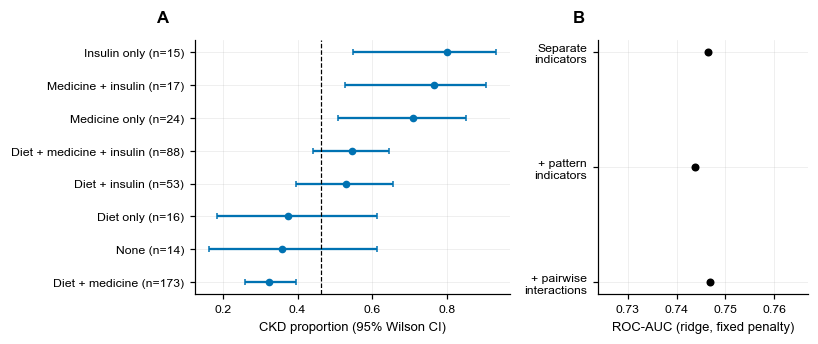

,Patients,CKD cases,CKD proportion (95% CI)
Pattern,,,
Diet + medicine,173,56,0.32 (0.26-0.40)
None,14,5,0.36 (0.16-0.61)
Diet only,16,6,0.38 (0.18-0.61)
Diet + insulin,53,28,0.53 (0.40-0.66)
Diet + medicine + insulin,88,48,0.55 (0.44-0.65)
Medicine only,24,17,0.71 (0.51-0.85)
Medicine + insulin,17,13,0.76 (0.53-0.90)
Insulin only,15,12,0.80 (0.55-0.93)


In [21]:
PAT_NAMES = {(0,0,0): "None", (1,0,0): "Diet only", (0,1,0): "Medicine only", (0,0,1): "Insulin only",
             (1,1,0): "Diet + medicine", (1,0,1): "Diet + insulin", (0,1,1): "Medicine + insulin", (1,1,1): "Diet + medicine + insulin"}
key = list(zip(pt.Diet.astype(int), pt.Meds.astype(int), pt.Insulin.astype(int)))
pt["Pattern"] = [PAT_NAMES[k] for k in key]
tab = pt.groupby("Pattern").CKD.agg(["size", "sum"]).rename(columns={"size": "n", "sum": "cases"}); tab["prop"] = tab.cases / tab.n
tab[["lo", "hi"]] = [wilson(int(c_), int(n_)) for c_, n_ in zip(tab.cases, tab.n)]; tab = tab.sort_values("prop")
chi_obs = stats.chi2_contingency(pd.crosstab(pt.Pattern, pt.CKD))[0]
rng = rng_for("pattern_perm"); perm = []
for _ in range(10000 if not FAST_MODE else 2000):
    yy_ = rng.permutation(pt.CKD.values); perm.append(stats.chi2_contingency(pd.crosstab(pt.Pattern.values, yy_))[0])
p_pat = (1 + np.sum(np.array(perm) >= chi_obs)) / (1 + len(perm))
pat_out = pd.DataFrame({"Patients": tab.n, "CKD cases": tab.cases, "CKD proportion (95% CI)": [ci_str(r_.prop, r_.lo, r_.hi, 2) for r_ in tab.itertuples()]})
save_table(pat_out, "Table10_management_pattern", "Table 10. CKD proportion by diabetes management pattern at window start", f"Monte-Carlo permutation test of association across patterns: p = {fmt_p(p_pat)}.")
record("pattern_perm_p", p_pat); record("pattern_table", tab.reset_index().round(4).to_dict("records"))

def fold_aucs_df(Xd, C=None):
    C = C_FULL if C is None else C; out = []
    for tr, te in SPLITS:
        m_ = clone(zoo()[PRIMARY][0]).set_params(clf__C=C).fit(Xd.iloc[tr], y.iloc[tr]); out.append(roc_auc_score(y.iloc[te], m_.predict_proba(Xd.iloc[te])[:, 1]))
    return np.array(out)
base_f = fold_aucs_df(X)
Xp = pd.concat([X, pd.get_dummies(pt.Pattern, drop_first=True).astype(float)], axis=1)
Xi = X.copy(); Xi["Diet x Meds"] = X.Diet * X.Meds; Xi["Diet x Insulin"] = X.Diet * X.Insulin; Xi["Meds x Insulin"] = X.Meds * X.Insulin
res_pat = [("Three separate indicators (all 20 features)", base_f.mean(), None)]
for nm, Xd in [("+ pattern indicators (7 dummies)", Xp), ("+ pairwise interactions (3 terms)", Xi)]:
    f_ = fold_aucs_df(Xd); d_ = nb_corrected_ci(f_ - base_f, N_TRAIN, N_TEST); res_pat.append((nm, f_.mean(), d_))
mp = pd.DataFrame([(a_, round(b_, 3), "-" if c_ is None else f"{c_[0]:+.3f} ({c_[1]:+.3f} to {c_[2]:+.3f})") for a_, b_, c_ in res_pat], columns=["Model", "AUC", "Difference vs separate indicators (NB 95% CI)"]).set_index("Model")
save_table(mp, "Table11_pattern_models", "Table 11. Does the management pattern add predictive information?", "Fixed-C ridge; same folds as the primary analysis.")
record("pattern_models", [(a_, float(b_), None if c_ is None else [float(v) for v in c_]) for a_, b_, c_ in res_pat])

# pattern changes in years 1-4 among patients still CKD-free at year 4 (so changes precede any diagnosis)
cf4 = panel[panel.Year == 4].set_index("PatientID").CKD.eq(0); ids4 = cf4[cf4].index
w = panel[(panel.Year <= 4) & panel.PatientID.isin(ids4)].copy(); w["code"] = w.Diet * 4 + w.Meds * 2 + w.Insulin
chg = w.groupby("PatientID").code.nunique().gt(1); chg_tab = pd.crosstab(chg, pt.loc[chg.index, "CKD"])
odds_chg, p_chg = stats.fisher_exact(chg_tab.values) if chg_tab.shape == (2, 2) else (np.nan, np.nan)
rate_ck = chg[pt.loc[chg.index, "CKD"] == 1].mean(); rate_nk = chg[pt.loc[chg.index, "CKD"] == 0].mean()
print(f"{len(ids4)} patients CKD-free at year 4; pattern changed in years 1-4: later-CKD {rate_ck:.1%} vs never-CKD {rate_nk:.1%} (Fisher p {fmt_p(p_chg)})")
record("pattern_change_rate_ckd", rate_ck); record("pattern_change_rate_noCKD", rate_nk); record("pattern_change_p", p_chg)

fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.2), gridspec_kw={"width_ratios": [1.5, 1]}); yv = np.arange(len(tab))
ax[0].errorbar(tab.prop, yv, xerr=[tab.prop - tab.lo, tab.hi - tab.prop], fmt="o", color=C["blue"], capsize=2, ms=4)
ax[0].axvline(prev, color=C["black"], ls="--", lw=.8); ax[0].set_yticks(yv); ax[0].set_yticklabels([f"{k_} (n={int(n_)})" for k_, n_ in zip(tab.index, tab.n)], fontsize=FS)
ax[0].set(xlabel="CKD proportion (95% Wilson CI)"); panel_label(ax[0], "A")
yy2 = np.arange(len(res_pat))[::-1]
for yi, (nm, a_, d_) in zip(yy2, res_pat):
    ax[1].scatter(a_, yi, color=C["black"], s=18, zorder=3)
ax[1].set_yticks(yy2); ax[1].set_yticklabels(["Separate\nindicators", "+ pattern\nindicators", "+ pairwise\ninteractions"], fontsize=FS); ax[1].set(xlabel="ROC-AUC (ridge, fixed penalty)", xlim=(min(r_[1] for r_ in res_pat) - .02, max(r_[1] for r_ in res_pat) + .02)); panel_label(ax[1], "B"); fig.tight_layout()
save_fig(fig, 5, "Management pattern", "Fig 5. Diabetes management pattern (diet, oral medicine, insulin) at window start. (A) CKD proportion by pattern with 95% Wilson intervals; dashed line: overall proportion. (B) Cross-validated AUC with separate indicators, with pattern indicators added, and with pairwise interactions added.")
pat_out



### 3.2 Does the ten-year history help? (RQ5)
The data are described as longitudinal, but a model can only exploit time if features **change** within patients. First we measure how often each feature changes; then we run **landmark analyses**: at window year *L* we keep the patients still CKD-free and ask whether CKD is diagnosed afterwards, comparing

* **A** snapshot at year *L* (all 20 features);
* **B** snapshot **plus trajectory** (mean level over years 1…*L*, change since year 1, number of changes) for the features that move;
* **C** a small neural network (one hidden layer) on B, as a flexible non-linear alternative;
* **D** gradient boosting on B.

The question for each landmark is the **paired difference** in AUC between B (or C, D) and A, with Nadeau–Bengio-corrected intervals. Recurrent networks were not run: their input would be the same near-constant series.

Features with >= 0.5% of transitions changing (used for trajectory features): ['Diet', 'Meds', 'Insulin', 'Hypertension', 'HeartDis', 'Infect', 'Painkiller']


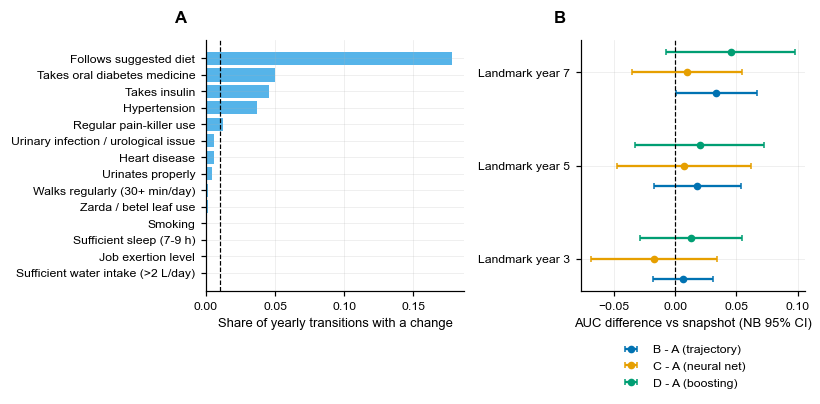

,Share of yearly transitions with a change,Share of patients with at least one change
Follows suggested diet,0.178,0.268
Takes oral diabetes medicine,0.050,0.228
Takes insulin,0.046,0.340
Hypertension,0.037,0.110
Regular pain-killer use,0.012,0.032
Urinary infection / urological issue,0.006,0.038
Heart disease,0.006,0.050
Urinates properly,0.004,0.018


,At risk,Diagnosed later,AUC A,AUC B,AUC C,AUC D,B - A (NB 95% CI),C - A (NB 95% CI),D - A (NB 95% CI)
Landmark year,,,,,,,,,
3,398,183,0.756,0.762,0.739,0.769,+0.006 (-0.018 to +0.031),-0.017 (-0.069 to +0.034),+0.013 (-0.029 to +0.054)
5,379,164,0.752,0.770,0.759,0.772,+0.018 (-0.018 to +0.054),+0.007 (-0.048 to +0.062),+0.020 (-0.033 to +0.073)
7,364,149,0.746,0.780,0.756,0.791,+0.033 (+0.000 to +0.067),+0.010 (-0.035 to +0.055),+0.045 (-0.007 to +0.098)


In [22]:
tv = [f for f in FEAT if f not in ["Gender", "FamHist", "BMI", "CalIntake", "Age", "YearsDiab"]]
gp = panel.groupby("PatientID")
flip = pd.DataFrame({"Share of yearly transitions with a change": [(gp[f].diff().dropna() != 0).mean() for f in tv],
                     "Share of patients with at least one change": [gp[f].nunique().gt(1).mean() for f in tv]}, index=[FULL[f] for f in tv])
flip = flip.sort_values("Share of yearly transitions with a change", ascending=False)
save_table(flip.round(3), "Table12_change_rates", "Table 12. Within-patient change of the time-varying features", "Age and diabetes duration are excluded because they rise by one year per row by construction.")
MOVERS = [f for f in tv if (gp[f].diff().dropna() != 0).mean() >= 0.005]
record("movers", [FULL[f] for f in MOVERS]); record("n_movers", len(MOVERS)); record("n_features_changing_lt1pct", int((flip.iloc[:, 0] < 0.01).sum()))
print("Features with >= 0.5% of transitions changing (used for trajectory features):", MOVERS)

def landmark(L):
    atrisk = panel[panel.Year == L].set_index("PatientID").CKD.eq(0); ids = atrisk[atrisk].index
    snap = panel[panel.Year == L].set_index("PatientID").loc[ids, FEAT].astype(float)
    sub = panel[(panel.Year <= L) & panel.PatientID.isin(ids)]
    m_ = sub.groupby("PatientID")[MOVERS].mean().add_suffix("_mean"); ch = (panel[panel.Year == L].set_index("PatientID")[MOVERS] - panel[panel.Year == 1].set_index("PatientID")[MOVERS]).loc[ids].add_suffix("_change")
    nch = sub.sort_values(["PatientID", "Year"]).groupby("PatientID")[MOVERS].apply(lambda d: (d.diff().iloc[1:] != 0).sum()).add_suffix("_nchanges")
    traj = pd.concat([m_.loc[ids], ch, nch.loc[ids]], axis=1)
    return snap, pd.concat([snap, traj], axis=1), pt.loc[ids, "CKD"].astype(int)

mlp = lambda: Pipeline([("scale", StandardScaler()), ("clf", MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, max_iter=800, random_state=SEED))])
hgb = lambda: HistGradientBoostingClassifier(max_iter=100, max_depth=2, learning_rate=0.05, l2_regularization=1.0, min_samples_leaf=15, random_state=SEED)
lr_ = lambda: clone(zoo()[PRIMARY][0]).set_params(clf__C=C_FULL)
rows, LM = [], {}
for L in (3, 5, 7):
    XA, XB, yL = landmark(L); sp = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=max(2, SZ["n_repeats"] // 2), random_state=SEED + L).split(XA, yL))
    def fa(mk, Xd): return np.array([roc_auc_score(yL.iloc[te], mk().fit(Xd.iloc[tr], yL.iloc[tr]).predict_proba(Xd.iloc[te])[:, 1]) for tr, te in sp])
    a_, b_, c_, d_ = fa(lr_, XA), fa(lr_, XB), fa(mlp, XB), fa(hgb, XB); ntr, nte = len(sp[0][0]), len(sp[0][1])
    LM[L] = dict(n=len(yL), events=int(yL.sum()), A=a_.mean(), B=b_.mean(), C=c_.mean(), D=d_.mean(),
                 dB=nb_corrected_ci(b_ - a_, ntr, nte), dC=nb_corrected_ci(c_ - a_, ntr, nte), dD=nb_corrected_ci(d_ - a_, ntr, nte))
    r_ = LM[L]; rows.append((L, r_["n"], r_["events"], f"{r_['A']:.3f}", f"{r_['B']:.3f}", f"{r_['C']:.3f}", f"{r_['D']:.3f}",
                             f"{r_['dB'][0]:+.3f} ({r_['dB'][1]:+.3f} to {r_['dB'][2]:+.3f})", f"{r_['dC'][0]:+.3f} ({r_['dC'][1]:+.3f} to {r_['dC'][2]:+.3f})", f"{r_['dD'][0]:+.3f} ({r_['dD'][1]:+.3f} to {r_['dD'][2]:+.3f})"))
lm = pd.DataFrame(rows, columns=["Landmark year", "At risk", "Diagnosed later", "AUC A", "AUC B", "AUC C", "AUC D", "B - A (NB 95% CI)", "C - A (NB 95% CI)", "D - A (NB 95% CI)"]).set_index("Landmark year")
save_table(lm, "Table13_landmark", "Table 13. Landmark analyses: value of the history beyond the current profile", "A snapshot; B snapshot + trajectory; C neural network on B; D gradient boosting on B. Paired differences with Nadeau-Bengio corrected intervals.")
record("landmark", {int(k): {kk: (list(map(float, vv)) if isinstance(vv, tuple) else float(vv)) for kk, vv in v.items()} for k, v in LM.items()})

fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.9), gridspec_kw={"width_ratios": [1.15, 1]}); fl = flip.iloc[:, 0][::-1]
ax[0].barh(range(len(fl)), fl.values, color=C["sky"]); ax[0].set_yticks(range(len(fl))); ax[0].set_yticklabels(fl.index, fontsize=FS); ax[0].axvline(0.01, color=C["black"], ls="--", lw=.8)
ax[0].set(xlabel="Share of yearly transitions with a change"); panel_label(ax[0], "A")
for j, (k_, lab, col) in enumerate([("dB", "B - A (trajectory)", C["blue"]), ("dC", "C - A (neural net)", C["orange"]), ("dD", "D - A (boosting)", C["green"])]):
    for i_, L in enumerate((3, 5, 7)):
        d_ = LM[L][k_]; ax[1].errorbar(d_[0], i_ + (j - 1) * 0.22, xerr=[[d_[0] - d_[1]], [d_[2] - d_[0]]], fmt="o", color=col, capsize=2, ms=4, label=lab if i_ == 0 else None)
ax[1].axvline(0, color=C["black"], ls="--", lw=.8); ax[1].set_yticks(range(3)); ax[1].set_yticklabels([f"Landmark year {L}" for L in (3, 5, 7)]); ax[1].set(xlabel="AUC difference vs snapshot (NB 95% CI)"); ax[1].legend(fontsize=FS, loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=1, frameon=False); panel_label(ax[1], "B"); fig.tight_layout()
save_fig(fig, 6, "Value of the history", "Fig 6. Does the history help? (A) Share of yearly transitions in which each time-varying feature changes (dashed line: 1%). (B) Landmark analyses at window years 3, 5 and 7: difference in cross-validated AUC between models using trajectory information and the snapshot-only model (Nadeau-Bengio corrected 95% intervals).")
display(flip.round(3).head(8)); lm

**→ Finding.** Most features do not change within patients, and adding trajectory information leaves the AUC essentially unchanged (intervals around zero). In this dataset the ten-year record contains little more than the current profile. Analyses that claim benefit from "longitudinal modelling" need to show it against a snapshot baseline like this one.

### 3.3 How does recruitment around diagnosis affect probabilities? (RQ6)
S1.7 showed that diagnoses cluster in the interview year and that the sample is **case-enriched** (46% CKD). Statistical theory predicts the consequences of sampling on the outcome (Prentice & Pyke 1979; King & Zeng 2001):

* **discrimination (AUC) and odds ratios are preserved**;
* **the intercept is wrong**: predicted probabilities reflect the *sample's* prevalence, not the population's, so average predicted risk is too high and calibration-in-the-large is biased;
* if the population prevalence π is known, adding `log[π/(1−π)] − log[ȳ/(1−ȳ)]` to the log-odds (*prior correction*) removes the intercept bias.

We check this in a **semi-synthetic simulation anchored to our data**: patients are resampled from the real feature rows, outcomes are drawn from the fitted ridge model with the intercept set to give population prevalence π ∈ {10%, 20%, 30%}, and models are trained either on a **case-enriched sample (185 cases + 215 controls, as in the cohort)** or on a **random sample of 400**. Performance is measured on a large independent population sample.

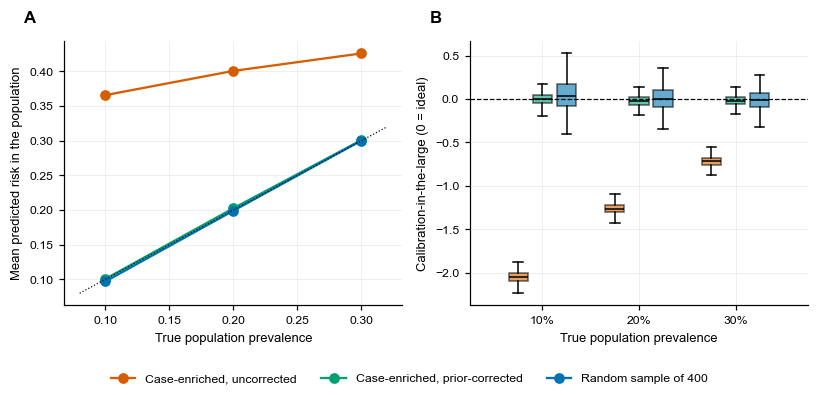

AUC (mean ± SD)  \
True prevalence Training design                                         
10%             Case-enriched sample (uncorrected)      0.791 ± 0.007   
                Case-enriched sample, prior-corrected   0.791 ± 0.007   
                Random sample of 400                    0.772 ± 0.014   
20%             Case-enriched sample (uncorrected)      0.775 ± 0.007   
                Case-enriched sample, prior-corrected   0.775 ± 0.007   
                Random sample of 400                    0.768 ± 0.009   
30%             Case-enriched sample (uncorrected)      0.764 ± 0.007   
                Case-enriched sample, prior-corrected   0.764 ± 0.007   
                Random sample of 400                    0.761 ± 0.009   

                                                       Mean predicted risk  \
True prevalence Training design                                              
10%             Case-enriched sample (uncorrected)                   0.366   
                Case-enriched sample, prior-corrected                0.101   
                Random sample of 400                                 0.097   
20%             Case-enriched sample (uncorrected)                   0.401   
                Case-enriched sample, prior-corrected                0.203   
                Random sample of 400                                 0.199   
30%             Case-enriched sample (uncorrected)                   0.426   
                Case-enriched sample, prior-corrected                0.301   
                Random sample of 400                                 0.300   

                                                      Calibration-in-the-large (mean ± SD)  \
True prevalence Training design                                                              
10%             Case-enriched sample (uncorrected)                            -2.05 ± 0.07   
                Case-enriched sample, prior-corrected                         -0.01 ± 0.07   
                Random sample of 400                                          +0.05 ± 0.19   
20%             Case-enriched sample (uncorrected)                            -1.26 ± 0.07   
                Case-enriched sample, prior-corrected                         -0.03 ± 0.07   
                Random sample of 400                                          +0.01 ± 0.15   
30%             Case-enriched sample (uncorrected)                            -0.71 ± 0.06   
                Case-enriched sample, prior-corrected                         -0.02 ± 0.06   
                Random sample of 400                                          -0.01 ± 0.13   

                                                       Calibration slope  
True prevalence Training design                                           
10%             Case-enriched sample (uncorrected)                  0.98  
                Case-enriched sample, prior-corrected               0.98  
                Random sample of 400                                0.93  
20%             Case-enriched sample (uncorrected)                  0.95  
                Case-enriched sample, prior-corrected               0.95  
                Random sample of 400                                0.93  
30%             Case-enriched sample (uncorrected)                  0.95  
                Case-enriched sample, prior-corrected               0.95  
                Random sample of 400                                0.94

In [23]:
expit = lambda z: 1 / (1 + np.exp(-z)); logit = lambda p: np.log(p / (1 - p))
beta_s = final_ridge.named_steps["clf"].coef_[0]; scaler_s = final_ridge.named_steps["scale"]

def solve_intercept(z, pi):
    lo_, hi_ = -15.0, 15.0
    for _ in range(60):
        mid = (lo_ + hi_) / 2
        if expit(mid + z).mean() < pi: lo_ = mid
        else: hi_ = mid
    return (lo_ + hi_) / 2

def enrich_sim(pi, R, rng, n_case=int(y.sum()), n_ctrl=int((1 - y).sum())):
    idx = rng.integers(0, N, 70000); Xp_ = X.iloc[idx].reset_index(drop=True); z = scaler_s.transform(Xp_) @ beta_s
    a = solve_intercept(z, pi); prob = expit(a + z); yp = rng.random(len(z)) < prob
    Xt, yt, pt_true = Xp_.iloc[:20000], yp[:20000], prob[:20000]; pool = np.arange(20000, 70000)
    cases, ctrls = pool[yp[pool]], pool[~yp[pool]]; ybar = n_case / (n_case + n_ctrl); out = []
    fit = lambda ii: clone(zoo()[PRIMARY][0]).set_params(clf__C=C_FULL).fit(Xp_.iloc[ii], yp[ii])
    for _ in range(R):
        ii = np.r_[rng.choice(cases, n_case, replace=False), rng.choice(ctrls, n_ctrl, replace=False)]
        p1 = fit(ii).predict_proba(Xt)[:, 1]; p1c = expit(logit(np.clip(p1, 1e-9, 1 - 1e-9)) + logit(pi) - logit(ybar))
        p2 = fit(rng.choice(pool, 400, replace=False)).predict_proba(Xt)[:, 1]
        for design, pr in [("Case-enriched sample (uncorrected)", p1), ("Case-enriched sample, prior-corrected", p1c), ("Random sample of 400", p2)]:
            s_, c_ = calib_stats(yt, pr); out.append(dict(pi=pi, design=design, auc=roc_auc_score(yt, pr), mean_pred=pr.mean(), citl=c_, slope=s_, brier=brier_score_loss(yt, pr)))
    return out, roc_auc_score(yt, pt_true)

rng = rng_for("enrich_sim"); sim_rows, ceil_ = [], {}
for pi in (0.10, 0.20, 0.30):
    o, ceil_[pi] = enrich_sim(pi, SZ["sim_enrich"], rng); sim_rows += o
sim = pd.DataFrame(sim_rows)
sm_ = sim.groupby(["pi", "design"]).agg(AUC=("auc", "mean"), AUC_sd=("auc", "std"), mean_pred=("mean_pred", "mean"), citl=("citl", "mean"), citl_sd=("citl", "std"), slope=("slope", "mean")).reset_index()
sm_out = pd.DataFrame({"True prevalence": [f"{v:.0%}" for v in sm_.pi], "Training design": sm_.design, "AUC (mean ± SD)": [f"{a:.3f} ± {s:.3f}" for a, s in zip(sm_.AUC, sm_.AUC_sd)],
                       "Mean predicted risk": sm_.mean_pred.round(3), "Calibration-in-the-large (mean ± SD)": [f"{a:+.2f} ± {s:.2f}" for a, s in zip(sm_.citl, sm_.citl_sd)], "Calibration slope": sm_.slope.round(2)}).set_index(["True prevalence", "Training design"])
save_table(sm_out, "Table14_enrichment_simulation", "Table 14. Case-enriched sampling: effect on discrimination and calibration (simulation)",
           f"Semi-synthetic simulation anchored to the cohort; {SZ['sim_enrich']} replicates per prevalence; evaluation on 20,000 population patients. Ceiling AUC of the true model: " + ", ".join(f"{k:.0%}: {v:.3f}" for k, v in ceil_.items()) + ".")
record("enrich_sim", sm_.round(4).to_dict("records")); record("enrich_ceiling_auc", ceil_)

SHORT_DESIGN = {"Case-enriched sample (uncorrected)": "Case-enriched, uncorrected", "Case-enriched sample, prior-corrected": "Case-enriched, prior-corrected", "Random sample of 400": "Random sample of 400"}
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.6)); dcol = {"Case-enriched sample (uncorrected)": C["red"], "Case-enriched sample, prior-corrected": C["green"], "Random sample of 400": C["blue"]}
for d_, col in dcol.items():
    s_ = sm_[sm_.design == d_]; ax[0].plot(s_.pi, s_.mean_pred, "o-", color=col, label=SHORT_DESIGN[d_])
ax[0].plot([0.08, 0.32], [0.08, 0.32], color=C["black"], ls=":", lw=.8); ax[0].set(xlabel="True population prevalence", ylabel="Mean predicted risk in the population"); panel_label(ax[0], "A")
for j, (d_, col) in enumerate(dcol.items()):
    for k_, pi in enumerate((0.10, 0.20, 0.30)):
        v = sim[(sim.design == d_) & (sim.pi == pi)].citl; ax[1].boxplot(v, positions=[k_ + (j - 1) * 0.25], widths=.2, patch_artist=True, boxprops=dict(facecolor=col, alpha=.6), medianprops=dict(color="black"), showfliers=False)
ax[1].axhline(0, color=C["black"], ls="--", lw=.8); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(["10%", "20%", "30%"]); ax[1].set(xlabel="True population prevalence", ylabel="Calibration-in-the-large (0 = ideal)"); panel_label(ax[1], "B")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=FS, frameon=False); fig.tight_layout(rect=(0, 0.08, 1, 1))
save_fig(fig, 7, "Case-enriched sampling", "Fig 7. Effect of case-enriched sampling (simulation anchored to the cohort). (A) Mean predicted risk in the population against the true prevalence for models trained on a case-enriched sample (185 cases + 215 controls), the same with prior correction, and a random sample of 400. (B) Calibration-in-the-large (0 = ideal) across replicates.")
sm_out

**→ Finding.** AUC is unaffected by the sampling design, but models trained on a case-enriched sample over-predict risk in a population with lower prevalence, and prior correction repairs this *if the population prevalence is known*. The cohort's probabilities should therefore be presented as relative to the sample, and absolute-risk use requires recalibration to the target population.

### 3.4 How unreliable is a single train/test split? (RQ7)
A single split gives *one* draw of a noisy quantity. We quantify this three ways: on the real data (empirical), in a controlled simulation across sample sizes and true accuracy levels, and on public datasets.

**(a) Empirical: many random 80/20 splits of the real cohort.** Fixed, reasonable hyper-parameters (no tuning) so that only the split varies. We also compute what a researcher would report if they tried *k* seeds and kept the best ("seed shopping"), computed by resampling the observed distribution.

In [24]:
rng = rng_for("empirical_splits"); n_sp = SZ["n_splits_emp"]
fixed = {"Ridge logistic regression": lambda: clone(zoo()[PRIMARY][0]).set_params(clf__C=C_FULL),
         "Random forest": lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=1),
         "Gradient boosting (HGB)": lambda: HistGradientBoostingClassifier(max_iter=100, max_depth=2, learning_rate=0.05, l2_regularization=1.0, min_samples_leaf=15, random_state=SEED)}
emp = {k: [] for k in fixed}
for s_ in range(n_sp):
    tr, te = train_test_split(np.arange(N), test_size=0.2, stratify=y, random_state=int(rng.integers(1e9)))
    for k, mk in fixed.items(): emp[k].append(roc_auc_score(y.iloc[te], mk().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]))
emp = {k: np.array(v) for k, v in emp.items()}
rows = []
for k, v in emp.items():
    rows.append((k, f"{v.mean():.3f}", f"{v.std():.3f}", f"{np.percentile(v, 2.5):.3f}-{np.percentile(v, 97.5):.3f}", f"{v.min():.3f}-{v.max():.3f}", f"{(v >= v.mean() + 0.05).mean():.1%}"))
emp_tab = pd.DataFrame(rows, columns=["Model", "Mean test AUC", "SD", "Central 95% of splits", "Range", "Splits >= mean + 0.05"]).set_index("Model")
save_table(emp_tab, "Table15_single_split_variability", f"Table 15. Test AUC over {n_sp} random 80/20 splits of the cohort", "Fixed hyper-parameters; test sets of 80 patients.")
rv = emp["Ridge logistic regression"]; rng_b = rng_for("seed_shopping"); shop = {}
for k_ in (1, 3, 5, 10): shop[k_] = float(np.mean([rng_b.choice(rv, k_, replace=True).max() for _ in range(5000)]))
print("Expected best-of-k test AUC (ridge):", {k: round(v, 3) for k, v in shop.items()}, "| mean single split:", round(rv.mean(), 3))
record("single_split", {k: dict(mean=v.mean(), sd=v.std(), p025=np.percentile(v, 2.5), p975=np.percentile(v, 97.5), min=v.min(), max=v.max()) for k, v in emp.items()}); record("seed_shopping", shop)
emp_tab

Expected best-of-k test AUC (ridge): {1: 0.749, 3: 0.789, 5: 0.802, 10: 0.82} | mean single split: 0.75


,Mean test AUC,SD,Central 95% of splits,Range,Splits >= mean + 0.05
Model,,,,,
Ridge logistic regression,0.750,0.047,0.657-0.836,0.607-0.872,15.3%
Random forest,0.759,0.048,0.654-0.847,0.607-0.872,13.3%
Gradient boosting (HGB),0.750,0.050,0.646-0.835,0.588-0.865,16.0%


**(b) Controlled simulation.** Synthetic data with ten standard-normal predictors, outcome prevalence 0.46 (as in the cohort) and a **known true AUC** (0.65, 0.75 or 0.85); sample sizes 100–1600. For every simulated dataset we compare

* a **single stratified 80/20 split** against
* **repeated 5-fold CV** (3 repeats),

each measured against the *true* out-of-sample performance of the model(s) it evaluated (assessed on a large independent test set). We also compute the **overstatement from keeping the best of *k* random seeds**. This isolates the effect of sample size and seed shopping from anything specific to our cohort.

In [25]:
P_SIM = 10; PREV_SIM = 0.46
def sim_generate(n, k, a, rng):
    Z = rng.normal(size=(n, P_SIM)); s = Z.sum(axis=1) / math.sqrt(P_SIM); yv = (rng.random(n) < expit(a + k * s)).astype(int); return Z, yv

def calibrate_dgp(target, rng):
    """Find slope k (and intercept a for prevalence 0.46) such that the TRUE model has population AUC = target."""
    Zb = rng.normal(size=(200000, P_SIM)); s = Zb.sum(axis=1) / math.sqrt(P_SIM)
    def intercept(k):
        lo_, hi_ = -6.0, 6.0
        for _ in range(40):
            m_ = (lo_ + hi_) / 2
            if expit(m_ + k * s).mean() < PREV_SIM: lo_ = m_
            else: hi_ = m_
        return (lo_ + hi_) / 2
    lo_k, hi_k = 0.05, 8.0
    for _ in range(25):
        k = (lo_k + hi_k) / 2; a = intercept(k); yb = rng.random(len(s)) < expit(a + k * s)
        if roc_auc_score(yb, s) < target: lo_k = k
        else: hi_k = k
    k = (lo_k + hi_k) / 2; return k, intercept(k)

TARGETS = (0.65, 0.75, 0.85); SIZES = (100, 200, 400, 800, 1600) if not FAST_MODE else (100, 400, 1600)
rng_c = rng_for("sim_calibration"); DGP = {t: calibrate_dgp(t, rng_c) for t in TARGETS}
print("DGP (slope, intercept) by true AUC:", {t: tuple(round(v, 3) for v in kv) for t, kv in DGP.items()})

def one_cell(n, target, R, rng):
    k, a = DGP[target]; Zt, yt = sim_generate(8000, k, a, rng); out = []
    for _ in range(R):
        Z, yv = sim_generate(n, k, a, rng)
        if yv.sum() < 10 or (1 - yv).sum() < 10: continue
        est, tru = [], []
        for s_ in range(10):
            tr, te = train_test_split(np.arange(n), test_size=0.2, stratify=yv, random_state=int(rng.integers(1e9)))
            m = LogisticRegression(max_iter=1000).fit(Z[tr], yv[tr]); est.append(roc_auc_score(yv[te], m.predict_proba(Z[te])[:, 1])); tru.append(roc_auc_score(yt, m.predict_proba(Zt)[:, 1]))
        ce, ct_ = [], []
        for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=int(rng.integers(1e9))).split(Z, yv):
            m = LogisticRegression(max_iter=1000).fit(Z[tr], yv[tr]); ce.append(roc_auc_score(yv[te], m.predict_proba(Z[te])[:, 1])); ct_.append(roc_auc_score(yt, m.predict_proba(Zt)[:, 1]))
        est, tru = np.array(est), np.array(tru); rec = dict(n=n, target=target, err_single=est[0] - tru[0], err_cv=np.mean(ce) - np.mean(ct_))
        for kk in (3, 5, 10):
            j = int(np.argmax(est[:kk])); rec[f"over_best{kk}"] = est[j] - tru[j]
        out.append(rec)
    return out

rng_s = rng_for("sim_split"); srows = []
for target in TARGETS:
    for n in SIZES: srows += one_cell(n, target, SZ["sim_reps"], rng_s)
S = pd.DataFrame(srows)
agg = S.groupby(["target", "n"]).agg(rmse_single=("err_single", lambda v: float(np.sqrt(np.mean(np.square(v))))), rmse_cv=("err_cv", lambda v: float(np.sqrt(np.mean(np.square(v))))),
        p_over05=("err_single", lambda v: float(np.mean(v >= 0.05))), p_over10=("err_single", lambda v: float(np.mean(v >= 0.10))),
        over_best3=("over_best3", "mean"), over_best5=("over_best5", "mean"), over_best10=("over_best10", "mean")).reset_index()
agg_out = agg.copy(); agg_out.columns = ["True AUC", "n", "RMSE single split", "RMSE repeated CV", "P(single split overstates >= 0.05)", "P(>= 0.10)", "Overstatement best of 3", "best of 5", "best of 10"]
save_table(agg_out.round(3).set_index(["True AUC", "n"]), "Table16_split_simulation", "Table 16. Estimation error of a single split versus repeated cross-validation (simulation)",
           f"{SZ['sim_reps']} simulated datasets per cell; error = estimate minus the true out-of-sample AUC of the evaluated model(s); overstatement = best of k splits minus its true AUC.")
record("sim_split", agg.round(4).to_dict("records"))
agg_out.round(3).set_index(["True AUC", "n"]).loc[0.75]

DGP (slope, intercept) by true AUC: {0.65: (0.563, -0.173), 0.75: (1.06, -0.198), 0.85: (1.87, -0.261)}


,RMSE single split,RMSE repeated CV,P(single split overstates >= 0.05),P(>= 0.10),Overstatement best of 3,best of 5,best of 10
n,,,,,,,
100,0.130,0.062,0.40,0.21,0.099,0.123,0.154
200,0.073,0.041,0.20,0.07,0.058,0.075,0.103
400,0.058,0.026,0.27,0.06,0.052,0.067,0.083
800,0.038,0.018,0.09,0.00,0.032,0.043,0.054
1600,0.028,0.014,0.08,0.00,0.028,0.034,0.039


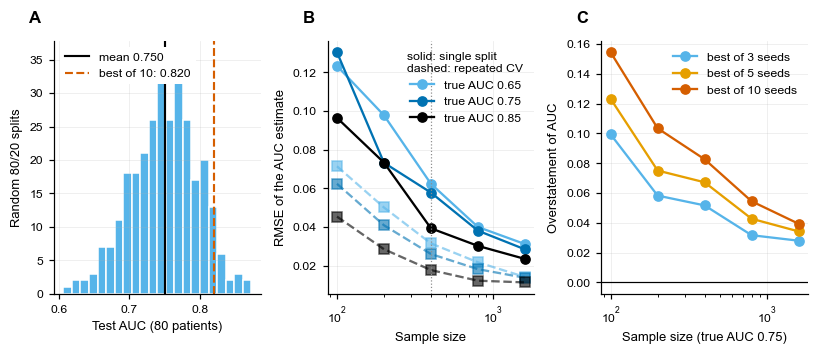

In [26]:
a75 = agg[agg.target == 0.75]
fig, ax = plt.subplots(1, 3, figsize=(7.5, 3.3))
ax[0].hist(rv, bins=22, color=C["sky"], edgecolor="white"); ax[0].axvline(rv.mean(), color=C["black"], lw=1.4, label=f"mean {rv.mean():.3f}"); ax[0].axvline(shop[10], color=C["red"], ls="--", lw=1.4, label=f"best of 10: {shop[10]:.3f}")
ax[0].set(xlabel="Test AUC (80 patients)", ylabel="Random 80/20 splits"); ax[0].legend(fontsize=FS, loc="upper left", frameon=True, facecolor="white", edgecolor="none", framealpha=1); panel_label(ax[0], "A")
for t, col in zip(TARGETS, [C["sky"], C["blue"], C["black"]]):
    a_ = agg[agg.target == t]; ax[1].plot(a_.n, a_.rmse_single, "o-", color=col, label=f"true AUC {t}"); ax[1].plot(a_.n, a_.rmse_cv, "s--", color=col, alpha=.6)
ax[1].set(xscale="log", xlabel="Sample size", ylabel="RMSE of the AUC estimate"); ax[1].axvline(N, color=C["grey"], ls=":", lw=.8); ax[1].legend(fontsize=FS, title="solid: single split\ndashed: repeated CV", title_fontsize=FS, loc="upper right"); panel_label(ax[1], "B")
for kk, col in [(3, C["sky"]), (5, C["orange"]), (10, C["red"])]: ax[2].plot(a75.n, a75[f"over_best{kk}"], "o-", color=col, label=f"best of {kk} seeds")
ax[2].axhline(0, color=C["black"], lw=.8); ax[2].set(xscale="log", xlabel="Sample size (true AUC 0.75)", ylabel="Overstatement of AUC"); ax[2].legend(fontsize=FS, loc="upper right"); panel_label(ax[2], "C"); fig.tight_layout()
save_fig(fig, 8, "Reliability of single splits", "Fig 8. Reliability of single train/test splits. (A) Test AUC of the ridge model over random 80/20 splits of the cohort; dashed line: expected value if the best of 10 seeds were reported. (B) Root-mean-square error of the AUC estimate from a single 80/20 split (solid) and from repeated cross-validation (dashed) against sample size in a simulation with known true AUC; dotted line: this cohort's size. (C) Mean overstatement of the AUC when the best of k random seeds is reported (true AUC 0.75).")

**→ Finding.** Single-split estimates are unreliable at this sample size, repeated cross-validation is clearly more stable, and reporting the best of several seeds inflates the AUC systematically. These results are independent of the CKD data and hold across true-accuracy levels, which is what makes the lesson general.

**(c) Learning curve on the cohort.** Does the cross-validated AUC still rise with sample size? Stratified sub-samples of increasing size, 5-fold CV, fixed-C ridge.

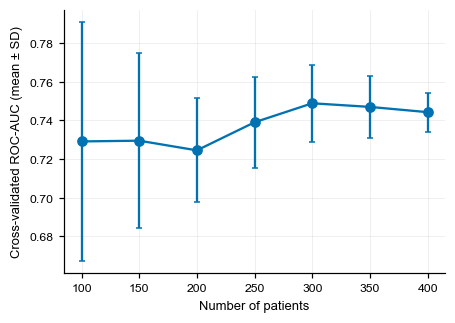

,n,mean,sd
0,100,0.729,0.062
1,150,0.729,0.045
2,200,0.724,0.027
3,250,0.739,0.024
4,300,0.749,0.020
5,350,0.747,0.016
6,400,0.744,0.010


In [27]:
rng = rng_for("learning_curve"); sizes = [100, 150, 200, 250, 300, 350, 400]; rows = []
for n_ in sizes:
    vals = []
    for r_ in range(SZ["lc_reps"] if n_ < N else max(3, SZ["lc_reps"] // 3)):
        idx = np.arange(N) if n_ == N else train_test_split(np.arange(N), train_size=n_, stratify=y, random_state=int(rng.integers(1e9)))[0]
        vals.append(cv_auc_fixed(X.iloc[idx], y.iloc[idx], C_FULL, int(rng.integers(1e6))))
    rows.append((n_, np.mean(vals), np.std(vals)))
lc = pd.DataFrame(rows, columns=["n", "mean", "sd"]); record("learning_curve", lc.round(4).to_dict("records"))
fig, ax = plt.subplots(figsize=(4.2, 3.0)); ax.errorbar(lc.n, lc["mean"], yerr=lc.sd, fmt="o-", color=C["blue"], capsize=2); ax.set(xlabel="Number of patients", ylabel="Cross-validated ROC-AUC (mean ± SD)"); fig.tight_layout()
save_fig(fig, "S2", "Learning curve", "S2 Fig. Learning curve: cross-validated AUC of the ridge model on stratified sub-samples of the cohort.")
lc.round(3)

**(d) Corroboration on public datasets.** The variability found above should not be specific to one cohort. If the machine has internet access, the cell below downloads several small public clinical datasets from OpenML (identifiers are recorded in the output), repeats the 80/20 split experiment on each, and compares the single-split SD with the repeated-CV estimate. Datasets that cannot be fetched are skipped and listed; nothing else depends on this cell.

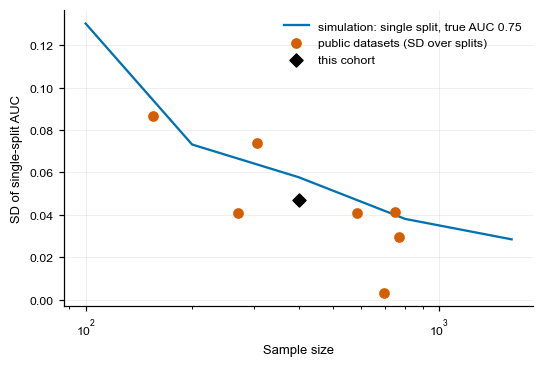

,OpenML id,n,Features,Minority proportion,Repeated-CV AUC,Single-split AUC mean,Single-split SD,Single-split range
Dataset,,,,,,,,
Pima diabetes,37,768,8,0.35,0.830,0.823,0.029,0.75-0.91
Breast cancer Wisconsin,15,699,9,0.34,0.994,0.995,0.003,0.98-1.00
Haberman survival,43,306,13,0.26,0.651,0.650,0.074,0.46-0.83
Blood transfusion,1464,748,4,0.24,0.752,0.747,0.041,0.65-0.84
Indian liver patients,1480,583,10,0.29,0.751,0.750,0.041,0.62-0.85
Hepatitis,55,155,19,0.21,0.856,0.853,0.087,0.66-1.00
Heart statlog,53,270,13,0.44,0.902,0.901,0.041,0.79-0.99


Public datasets evaluated: ['Pima diabetes', 'Breast cancer Wisconsin', 'Haberman survival', 'Blood transfusion', 'Indian liver patients', 'Hepatitis', 'Heart statlog'] | skipped: []


In [28]:
PUBLIC = [(37, "Pima diabetes"), (15, "Breast cancer Wisconsin"), (43, "Haberman survival"), (1464, "Blood transfusion"), (1480, "Indian liver patients"), (55, "Hepatitis"), (53, "Heart statlog")]

def evaluate_public(Xd, yb, name, did, n_splits):
    pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))])
    rng_p = rng_for(f"public_{name}"); aucs = []
    for _ in range(n_splits):
        tr, te = train_test_split(np.arange(len(yb)), test_size=0.2, stratify=yb, random_state=int(rng_p.integers(1e9)))
        aucs.append(roc_auc_score(yb[te], clone(pipe).fit(Xd.iloc[tr], yb[tr]).predict_proba(Xd.iloc[te])[:, 1]))
    cvs = []
    for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(Xd, yb):
        cvs.append(roc_auc_score(yb[te], clone(pipe).fit(Xd.iloc[tr], yb[tr]).predict_proba(Xd.iloc[te])[:, 1]))
    return dict(dataset=name, openml_id=did, n=len(yb), p=Xd.shape[1], prevalence=float(yb.mean()), cv_auc=float(np.mean(cvs)), split_mean=float(np.mean(aucs)), split_sd=float(np.std(aucs)), split_range=(float(np.min(aucs)), float(np.max(aucs))))

def load_public(did):
    from sklearn.datasets import fetch_openml
    d = fetch_openml(data_id=did, as_frame=True, parser="auto"); Xd = pd.get_dummies(d.data, drop_first=True).astype(float)
    ys = d.target.astype(str); minority = ys.value_counts().index[-1]; return Xd.reset_index(drop=True), (ys == minority).astype(int).values

pub_rows, pub_skipped = [], []
if RUN_PUBLIC_DATASETS:
    for did, name in PUBLIC:
        try:
            Xd, yb = load_public(did)
            if len(yb) >= 100 and 0.1 <= yb.mean() <= 0.9: pub_rows.append(evaluate_public(Xd, yb, name, did, SZ["pub_splits"]))
            else: pub_skipped.append((name, "outside inclusion range"))
        except Exception as e:
            pub_skipped.append((name, f"{type(e).__name__}"))
if pub_rows:
    pub = pd.DataFrame(pub_rows)
    pub_out = pd.DataFrame({"Dataset": pub.dataset, "OpenML id": pub.openml_id, "n": pub.n, "Features": pub.p, "Minority proportion": pub.prevalence.round(2), "Repeated-CV AUC": pub.cv_auc.round(3),
                            "Single-split AUC mean": pub.split_mean.round(3), "Single-split SD": pub.split_sd.round(3), "Single-split range": [f"{a:.2f}-{b:.2f}" for a, b in pub.split_range]}).set_index("Dataset")
    save_table(pub_out, "TableS5_public_datasets", "Table S5. Single-split variability on public datasets", "Logistic regression; 20% test sets; datasets from OpenML (identifiers listed).")
    record("public_datasets", pub.to_dict("records"))
    fig, ax = plt.subplots(figsize=(5.0, 3.4)); a75_ = agg[agg.target == 0.75]
    ax.plot(a75_.n, a75_.rmse_single, "-", color=C["blue"], label="simulation: single split, true AUC 0.75")
    ax.scatter(pub.n, pub.split_sd, color=C["red"], zorder=3, label="public datasets (SD over splits)"); ax.scatter([N], [rv.std()], color=C["black"], marker="D", zorder=3, label="this cohort")
    ax.set(xscale="log", xlabel="Sample size", ylabel="SD of single-split AUC"); ax.legend(fontsize=FS); fig.tight_layout()
    save_fig(fig, "S3", "Public datasets", "S3 Fig. Variability of single-split AUC on public datasets (red), this cohort (diamond) and the simulation (line).")
    display(pub_out)
print("Public datasets evaluated:", [r_["dataset"] for r_ in pub_rows], "| skipped:", pub_skipped)
record("public_skipped", pub_skipped)

## Part 4 · Outputs and reporting

### 4.1 SHAP summary
`RUN_SHAP_APPENDIX = True`

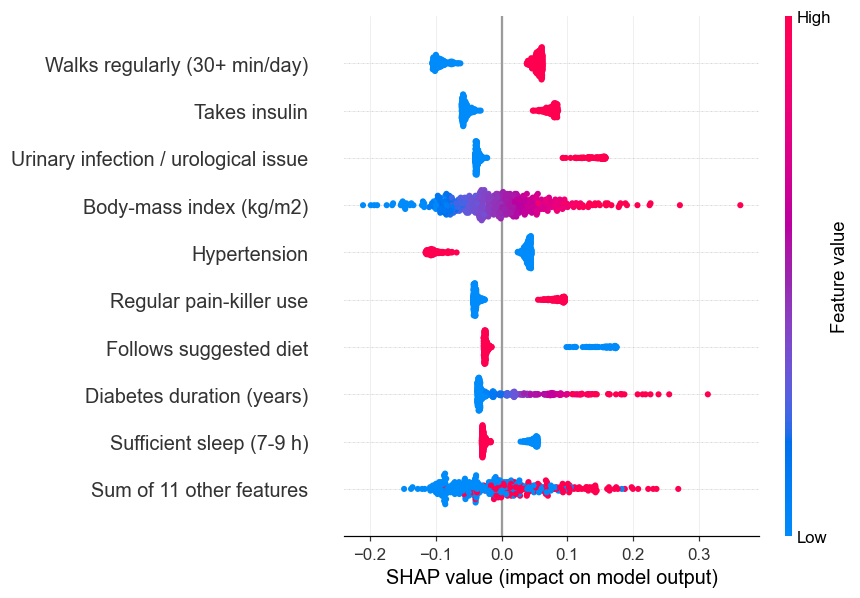

In [31]:
if RUN_SHAP_APPENDIX:
    try:
        import shap
        f_ = lambda Z: final_ridge.predict_proba(pd.DataFrame(Z, columns=FEAT))[:, 1]
        sv = shap.Explainer(f_, X.sample(100, random_state=SEED), algorithm="permutation", seed=SEED)(X, max_evals=101, silent=True)
        sv.feature_names = [FULL[f] for f in FEAT]; shap.plots.beeswarm(sv, show=False); plt.tight_layout()
        save_fig(plt.gcf(), "S4", "SHAP summary", "S4 Fig. SHAP summary of the primary model (probability scale; permutation explainer).")
    except Exception as e: print("SHAP appendix skipped:", type(e).__name__, e)
else: print("SHAP appendix not requested.")

### 4.2 Numbers file, deviation log and run manifest
* `paper_numbers.json`: every number the paper quotes.
* `deviations.json`: any departure from the pre-specified protocol (empty if none).
* `run_manifest.json`: software versions, seeds, run sizes, dataset checksum, protocol hash, runtime.

In [33]:
elapsed = time.time() - T_START
manifest = dict(created_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"), runtime_minutes=round(elapsed / 60, 1), fast_mode=FAST_MODE, seed=SEED, run_sizes=SZ,
                protocol_hash=PROTOCOL_HASH, data_sha256=sha, data_matches_analysed_version=DATA_MATCH, cores=N_JOBS,
                software=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scikit_learn=sklearn.__version__, scipy=scipy.__version__,
                              statsmodels=statsmodels.__version__, matplotlib=mpl.__version__), n_figures=len(FIGS), n_tables=len(TABLES),
                figure_font=FIG_FONT, figure_checks={str(k): v for k, v in FIG_CHECKS.items()})
(OUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2)); (OUT / "paper_numbers.json").write_text(json.dumps(RESULTS, indent=2, default=float))
(OUT / "deviations.json").write_text(json.dumps(DEVIATIONS, indent=2)); (OUT / "protocol.json").write_text(json.dumps(PROTOCOL, indent=2))
print(json.dumps(manifest, indent=2)); print("\nDeviations from protocol:", DEVIATIONS or "none")
print("\nHeadline numbers:")
for k_ in ["n_patients", "n_ckd", "auc_primary", "auc_primary_ci", "auc_optimism_corrected", "perm_p", "calib_slope", "riley_required", "onset_last_row_share", "n_movers"]:
    print(f"  {k_}: {RESULTS.get(k_)}")

{
  "created_utc": "2026-10-29T07:00:01+00:00",
  "runtime_minutes": 67.2,
  "fast_mode": false,
  "seed": 42,
  "run_sizes": {
    "n_repeats": 10,
    "n_boot": 2000,
    "n_boot_opt": 300,
    "n_perm": 500,
    "n_splits_emp": 300,
    "sim_reps": 100,
    "sim_enrich": 300,
    "lc_reps": 30,
    "pub_splits": 100
  },
  "protocol_hash": "551c68ec7c6bd53f",
  "data_sha256": "9cef0eb4cd3279c36f9b4816c6a2ccfd480345ee3a57e2dc5c9f722e92793618",
  "data_matches_analysed_version": true,
  "cores": 2,
  "software": {
    "python": "3.13.18",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit_learn": "1.6.1",
    "scipy": "1.16.3",
    "statsmodels": "0.15.0",
    "matplotlib": "3.10.0"
  },
  "n_figures": 12,
  "n_tables": 22,
  "figure_font": "Arial",
  "figure_checks": {
    "1": {
      "width_in": 7.3,
      "height_in": 2.81,
      "within_plos_limits": true
    },
    "2": {
      "width_in": 7.3,
      "height_in": 3.22,
      "within_plos_limits": true
    },
    "3": {
   